# Plot similar to Jannidis et al. (2015)

In [40]:
import pandas as pd
#pd.set_option('display.max_rows', None)
import numpy as np
import matplotlib.pyplot as plt
from tqdm import tqdm

In [41]:
eval_en = pd.read_feather("../Results/evaluation/refcor_en_l1g_eval_list_res.feather")
eval_de = pd.read_feather("../Results/evaluation/refcor_de_l1g_eval_list_res.feather")
eval_fr = pd.read_feather("../Results/evaluation/refcor_fr_l1g_eval_list_res.feather")
eval_ice = pd.read_feather("../Results/evaluation/refcor_ice_l1g_eval_list_res.feather")

In [42]:
eval_en["distance"] = eval_en["distance"].astype(str)
eval_de["distance"] = eval_de["distance"].astype(str)
eval_fr["distance"] = eval_fr["distance"].astype(str)
eval_ice["distance"] = eval_ice["distance"].astype(str)

In [ ]:
# # Define new rows for "Rotated Delta"
# new_rows = pd.DataFrame([
#     {"distance": "Rotated Delta", "step": 100,},
#     {"distance": "Rotated Delta", "step": 1000},
#     {"distance": "Rotated Delta", "step": 5000}
# ])

# # Append to each DataFrame using pd.concat()
# eval_en = pd.concat([eval_en, new_rows], ignore_index=True)
# eval_de = pd.concat([eval_de, new_rows], ignore_index=True)
# eval_fr = pd.concat([eval_fr, new_rows], ignore_index=True)
# eval_ice = pd.concat([eval_ice, new_rows], ignore_index=True)

eval_en["language"] = "English"
eval_de["language"] = "German"
eval_fr["language"] = "French"
eval_ice["language"] = "Icelandic"

In [44]:
# correct Euclidian to Euclidean, Eder's Simple to Eder's Simple Delta
eval_en["distance"] = eval_en["distance"].replace({"Euclidian": "Euclidean", "Eder's Simple": "Eder's Simple Delta"})
eval_de["distance"] = eval_de["distance"].replace({"Euclidian": "Euclidean", "Eder's Simple": "Eder's Simple Delta"})
eval_fr["distance"] = eval_fr["distance"].replace({"Euclidian": "Euclidean", "Eder's Simple": "Eder's Simple Delta"})
eval_ice["distance"] = eval_ice["distance"].replace({"Euclidian": "Euclidean", "Eder's Simple": "Eder's Simple Delta"})

In [221]:
eval_all = pd.concat([eval_en, eval_de, eval_fr, eval_ice], ignore_index=True)

In [47]:
eval_en["distance"].unique()

array(['Quadratic Delta', "Burrows' Delta", 'Cosine', 'Cosine Delta',
       "Eder's Simple Delta", "Eder's Delta", 'Entropy', 'Min-Max',
       'Euclidean', 'Manhattan', 'Canberra', 'Chebyshev', 'Linear Delta',
       "Hoover's P1 Delta", 'Bray-Curtis', 'Correlation'], dtype=object)

In [34]:
def sort_eval_values_at_mff(df):
    max_performance = df.groupby(["distance"]).agg({"simple_score": "max", "cl_error": "min", "ari": "max"}).reset_index()
    max_performance["rank1"] = max_performance["simple_score"].rank(ascending=False)
    max_performance["rank2"] = max_performance["cl_error"].rank(ascending=True)
    max_performance["rank3"] = max_performance["ari"].rank(ascending=False)
    max_performance["mean_rank"] = max_performance[["rank1", "rank2", "rank3"]].mean(axis=1)
    max_performance["median_rank"] = max_performance[["rank1", "rank2", "rank3"]].median(axis=1)
    max_performance["sum_rank"] = max_performance[["rank1", "rank2", "rank3"]].sum(axis=1)
    max_performance = max_performance.sort_values(by=["mean_rank"], ascending=True)
    highrank = max_performance.sort_values(by=["mean_rank"], ascending=True)["distance"].tolist()
    return max_performance, highrank

def scatter_for_eval(df, n, eval_score, n_dist, max_x, yticks=False, xticks_list=[], colour="red"):
    plt.title(f"{n} MFW")
    df_at_n = df[df["step"]==n].sort_values(by=["highrank"], ascending=True).reset_index()
    
    plt.hlines(y=range(1, n_dist), xmin=0, xmax=max_x, color="black", alpha=0.3)
    plt.scatter(df_at_n[eval_score], range(1,n_dist), c=colour)
    
    if yticks:
        plt.yticks(np.arange(1, n_dist), df_at_n["distance"], rotation=0)
    else:
        plt.yticks([])

    if xticks_list:
        plt.xticks(xticks_list)
    else:
        plt.xticks([])

def plot_results_of_eval(res, num_distances, title=None, colour="red"):
    fig = plt.subplots(figsize=(15,15), nrows=3, ncols=3)
    
    max_x = 4 # from paper else #max(res["simple_score"]+0.1)
    x_list = [0, 1, 2, 3]
    plt.subplot(3,3,7)
    scatter_for_eval(res, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=colour)
    plt.xlabel("diff between z-transformed means")
    plt.subplot(3,3,4)
    scatter_for_eval(res, 1000, "simple_score", num_distances, max_x, yticks=True, colour=colour)
    plt.subplot(3,3,1)
    scatter_for_eval(res, 5000, "simple_score", num_distances, max_x, yticks=True, colour=colour)
    
    max_x = 1
    x_list = [0, 0.2, 0.4, 0.6, 0.8]
    plt.subplot(3,3,8)
    scatter_for_eval(res, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=colour)
    plt.xlabel("Adjusted Rand Index")
    plt.subplot(3,3,5)
    scatter_for_eval(res, 1000, "ari", num_distances, max_x, colour=colour)
    plt.subplot(3,3,2)
    scatter_for_eval(res, 5000, "ari", num_distances, max_x, colour=colour)
    
    max_x = 40#from paper else #max(res["cl_error"])
    x_list = [0, 10, 20, 30, 40]
    plt.subplot(3,3,9)
    scatter_for_eval(res, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=colour)
    plt.xlabel("Cluster Errors")
    plt.subplot(3,3,6)
    scatter_for_eval(res, 1000, "cl_error", num_distances, max_x, colour=colour)
    plt.subplot(3,3,3)
    scatter_for_eval(res, 5000, "cl_error", num_distances, max_x, colour=colour)
    plt.rcParams.update({'font.size': 20})# standard 18
    plt.tight_layout()
    plt.show()

In [48]:
refcor_highrank_all = [ 'Cosine Delta',
 "Burrows' Delta",
 "Eder's Delta",
 "Hoover's P1 Delta",
 'Linear Delta',
 "Eder's Simple Delta",
 'Bray-Curtis',
 'Canberra',
 'Manhattan',
 'Quadratic Delta',
 'Euclidean',
 'Correlation',
 'Cosine',
 'Chebyshev',
 #'Rotated Delta',
 'Entropy',
 'Min-Max']

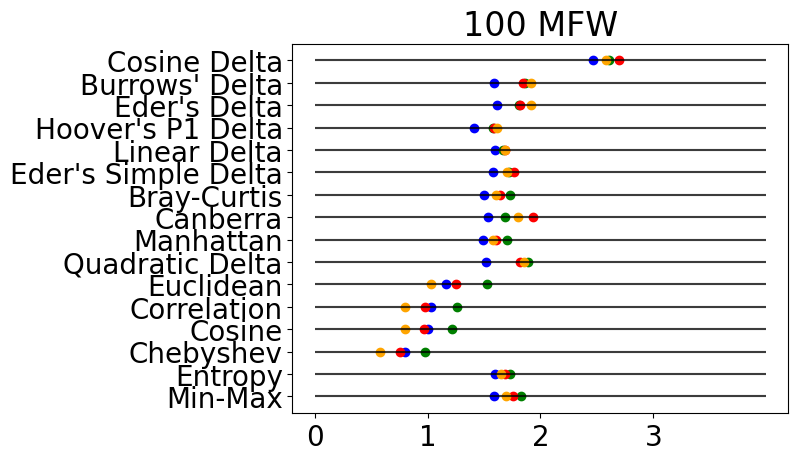

In [49]:
#max_performance, highrank = sort_eval_values_at_mff(eval_en)
highrank = refcor_highrank_all[::-1]
# only distances that are in the highrank list
eval_en["distance"] = eval_en["distance"].astype(str)
refcor_highrank_en = [str(x) for x in refcor_highrank_all]
eval_en = eval_en[eval_en["distance"].isin(refcor_highrank_en)]
eval_en["highrank"] = eval_en["distance"].apply(lambda x: highrank.index(x))

# de
eval_de["distance"] = eval_de["distance"].astype(str)
refcor_highrank_de = [str(x) for x in refcor_highrank_all]
eval_de = eval_de[eval_de["distance"].isin(refcor_highrank_de)]
eval_de["highrank"] = eval_de["distance"].apply(lambda x: highrank.index(x))

# fr
eval_fr["distance"] = eval_fr["distance"].astype(str)
refcor_highrank_fr = [str(x) for x in refcor_highrank_all]
eval_fr = eval_fr[eval_fr["distance"].isin(refcor_highrank_fr)]
eval_fr["highrank"] = eval_fr["distance"].apply(lambda x: highrank.index(x))

# ice
eval_ice["distance"] = eval_ice["distance"].astype(str)
refcor_highrank_ice = [str(x) for x in refcor_highrank_all]
eval_ice = eval_ice[eval_ice["distance"].isin(refcor_highrank_ice)]
eval_ice["highrank"] = eval_ice["distance"].apply(lambda x: highrank.index(x))

scatter_for_eval(eval_en, 100, "simple_score", len(refcor_highrank_all)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="blue")
scatter_for_eval(eval_fr, 100, "simple_score", len(refcor_highrank_all)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="green")
scatter_for_eval(eval_de, 100, "simple_score", len(refcor_highrank_all)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="red")
scatter_for_eval(eval_ice, 100, "simple_score", len(refcor_highrank_all)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="orange")


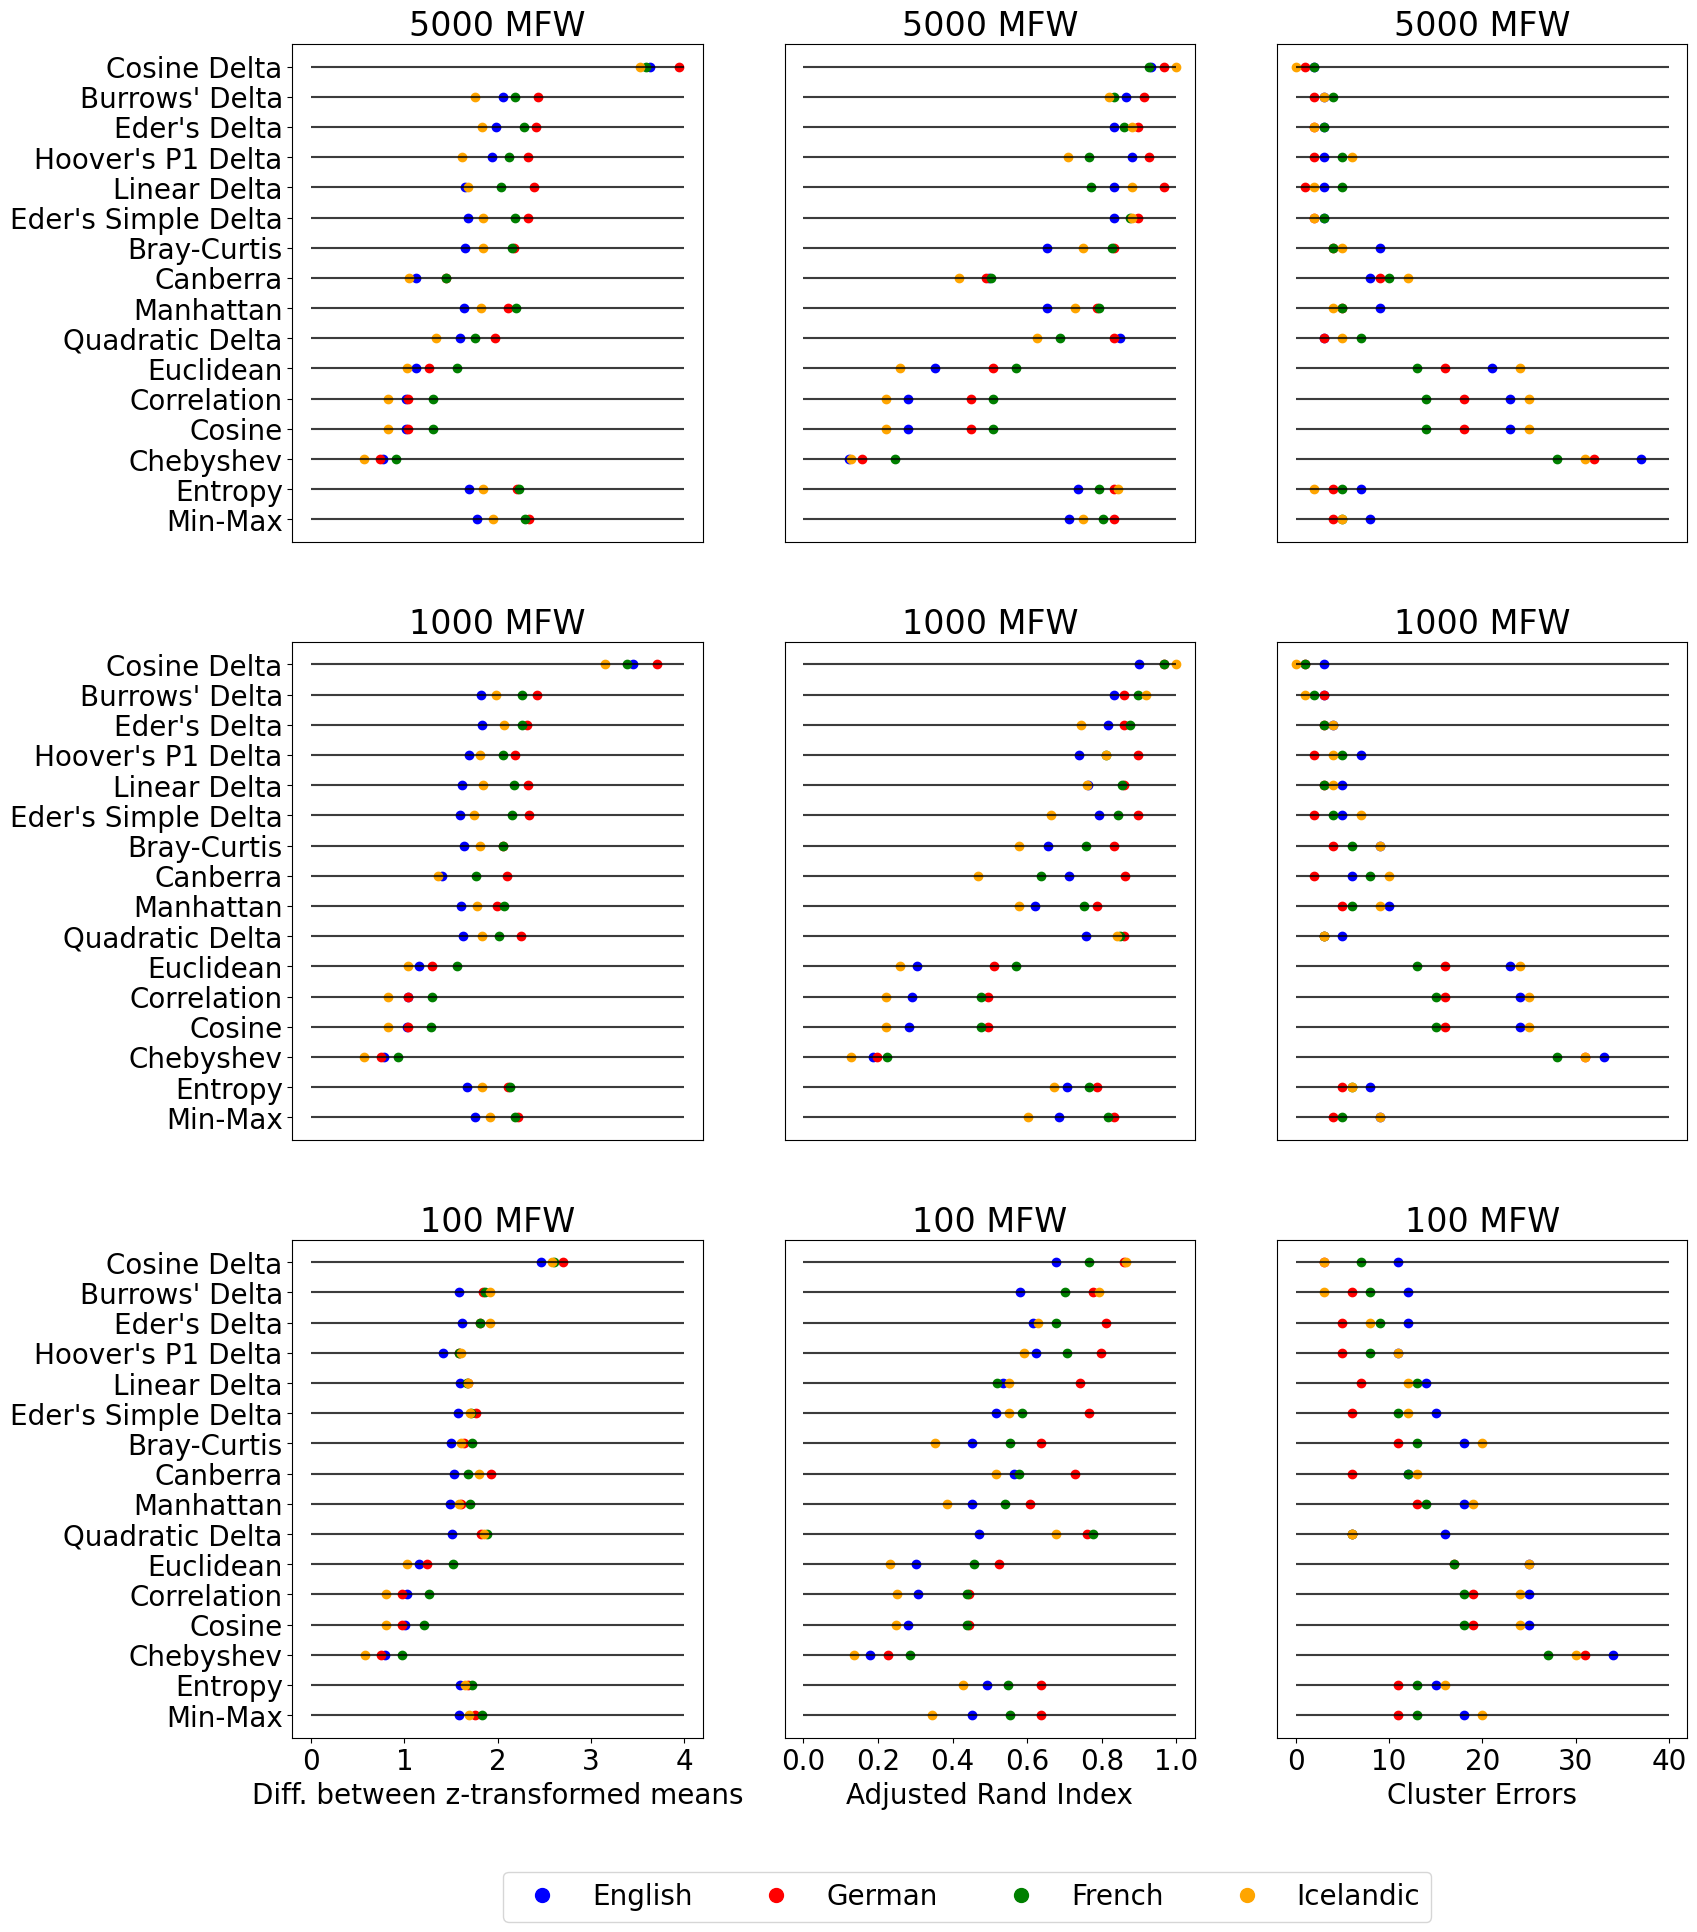

In [65]:

fig, axes = plt.subplots(figsize=(18,22), nrows=3, ncols=3) #18,18

num_distances = len(refcor_highrank_all)+1
col_en = "blue"
col_de = "red"
col_fr = "green"
col_ice = "orange"

# === SIMPLE SCORE ===
max_x = 4
x_list = [0, 1, 2, 3, 4]

plt.subplot(3,3,7)
scatter_for_eval(eval_en, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_ice)
plt.xlabel("Diff. between z-transformed means")

plt.subplot(3,3,4)
scatter_for_eval(eval_en, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_en)
scatter_for_eval(eval_de, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_de)
scatter_for_eval(eval_fr, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_ice)

plt.subplot(3,3,1)
scatter_for_eval(eval_en, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_en)
scatter_for_eval(eval_de, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_de)
scatter_for_eval(eval_fr, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_ice)

# === ARI ===
max_x = 1
x_list = [0, 0.2, 0.4, 0.6, 0.8, 1]

plt.subplot(3,3,8)
scatter_for_eval(eval_en, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_ice)
plt.xlabel("Adjusted Rand Index")

plt.subplot(3,3,5)
scatter_for_eval(eval_en, 1000, "ari", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 1000, "ari", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 1000, "ari", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "ari", num_distances, max_x, colour=col_ice)

plt.subplot(3,3,2)
scatter_for_eval(eval_en, 5000, "ari", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 5000, "ari", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 5000, "ari", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "ari", num_distances, max_x, colour=col_ice)

# === CLUSTER ERRORS ===
max_x = 40
x_list = [0, 10, 20, 30, 40]

plt.subplot(3,3,9)
scatter_for_eval(eval_en, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "cl_error", num_distances, max_x, xticks_list=x_list, colour=col_ice)
plt.xlabel("Cluster Errors")

plt.subplot(3,3,6)
scatter_for_eval(eval_en, 1000, "cl_error", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 1000, "cl_error", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 1000, "cl_error", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "cl_error", num_distances, max_x, colour=col_ice)

plt.subplot(3,3,3)
scatter_for_eval(eval_en, 5000, "cl_error", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 5000, "cl_error", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 5000, "cl_error", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "cl_error", num_distances, max_x, colour=col_ice)

# HARD-CODED LEGEND
# legend bellow the plot EN=Blue, DE=Red, FR=Green, ICE=Orange
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([], [], color=col_en, marker='o', markersize=10, linestyle='', label="English"),
    Line2D([], [], color=col_de, marker='o', markersize=10, linestyle='', label="German"),
    Line2D([], [], color=col_fr, marker='o', markersize=10, linestyle='', label="French"),
    Line2D([], [], color=col_ice, marker='o', markersize=10, linestyle='', label="Icelandic")
]

# Attach legend to the figure, not to any subplot
fig.legend(
    handles=legend_elements,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.02),  # adjust as needed
    ncol=4,
    fontsize=20
)

plt.rcParams.update({'font.size': 20})
#plt.tight_layout()
plt.show()

In [64]:
break;
fig, axes = plt.subplots(figsize=(18,22), nrows=3, ncols=3) #18,18

num_distances = len(refcor_highrank_all)+1
col_en = "blue"
col_de = "red"
col_fr = "green"
col_ice = "orange"

# === SIMPLE SCORE ===
max_x = 4
x_list = [0, 1, 2, 3, 4]

plt.subplot(3,3,7)
scatter_for_eval(eval_en, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "simple_score", num_distances, max_x, yticks=True, xticks_list=x_list, colour=col_ice)
plt.xlabel("Diff. between z-transformed means")

plt.subplot(3,3,4)
scatter_for_eval(eval_en, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_en)
scatter_for_eval(eval_de, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_de)
scatter_for_eval(eval_fr, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "simple_score", num_distances, max_x, yticks=True, colour=col_ice)

plt.subplot(3,3,1)
scatter_for_eval(eval_en, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_en)
scatter_for_eval(eval_de, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_de)
scatter_for_eval(eval_fr, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "simple_score", num_distances, max_x, yticks=True, colour=col_ice)

# === ARI ===
max_x = 1
x_list = [0, 0.2, 0.4, 0.6, 0.8, 1]

plt.subplot(3,3,8)
scatter_for_eval(eval_en, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "ari", num_distances, max_x, xticks_list=x_list, colour=col_ice)
plt.xlabel("Adjusted Rand Index")

plt.subplot(3,3,5)
scatter_for_eval(eval_en, 1000, "ari", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 1000, "ari", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 1000, "ari", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "ari", num_distances, max_x, colour=col_ice)

plt.subplot(3,3,2)
scatter_for_eval(eval_en, 5000, "ari", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 5000, "ari", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 5000, "ari", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "ari", num_distances, max_x, colour=col_ice)

# === CLUSTER ERRORS ===
max_x = 1
x_list = [0, 0.2, 0.4, 0.6, 0.8, 1]

plt.subplot(3,3,9)
scatter_for_eval(eval_en, 100, "cl_correct_pc", num_distances, max_x, xticks_list=x_list, colour=col_en)
scatter_for_eval(eval_de, 100, "cl_correct_pc", num_distances, max_x, xticks_list=x_list, colour=col_de)
scatter_for_eval(eval_fr, 100, "cl_correct_pc", num_distances, max_x, xticks_list=x_list, colour=col_fr)
scatter_for_eval(eval_ice, 100, "cl_correct_pc", num_distances, max_x, xticks_list=x_list, colour=col_ice)
plt.xlabel("% of Correct Clusters")

plt.subplot(3,3,6)
scatter_for_eval(eval_en, 1000, "cl_correct_pc", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 1000, "cl_correct_pc", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 1000, "cl_correct_pc", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 1000, "cl_correct_pc", num_distances, max_x, colour=col_ice)

plt.subplot(3,3,3)
scatter_for_eval(eval_en, 5000, "cl_correct_pc", num_distances, max_x, colour=col_en)
scatter_for_eval(eval_de, 5000, "cl_correct_pc", num_distances, max_x, colour=col_de)
scatter_for_eval(eval_fr, 5000, "cl_correct_pc", num_distances, max_x, colour=col_fr)
scatter_for_eval(eval_ice, 5000, "cl_correct_pc", num_distances, max_x, colour=col_ice)

# HARD-CODED LEGEND
# legend bellow the plot EN=Blue, DE=Red, FR=Green, ICE=Orange
from matplotlib.lines import Line2D

legend_elements = [
    Line2D([], [], color=col_en, marker='o', markersize=10, linestyle='', label="English"),
    Line2D([], [], color=col_de, marker='o', markersize=10, linestyle='', label="German"),
    Line2D([], [], color=col_fr, marker='o', markersize=10, linestyle='', label="French"),
    Line2D([], [], color=col_ice, marker='o', markersize=10, linestyle='', label="Icelandic")
]

# Attach legend to the figure, not to any subplot
fig.legend(
    handles=legend_elements,
    loc='lower center',
    bbox_to_anchor=(0.5, 0.02),  # adjust as needed
    ncol=4,
    fontsize=20
)

plt.rcParams.update({'font.size': 20})
#plt.tight_layout()
plt.show()

SyntaxError: 'break' outside loop (2710675554.py, line 1)

In [ ]:
print(", ".join(sort_eval_values_at_mff(eval_ice)[0].sort_values(by=["simple_score"], ascending=True)["distance"].to_list()))

Correlation, Cosine, Chebyshev, Euclidean, Canberra, Manhattan, Bray-Curtis, Entropy, Linear Delta, Hoover's P1 Delta, Min-Max, Quadratic Delta, Burrows' Delta, Eder's Delta, Eder's Simple Delta, Cosine Delta


In [61]:
sort_eval_values_at_mff(eval_ice)[0]

,distance,simple_score,cl_error,ari,rank1,rank2,rank3,mean_rank,median_rank,sum_rank
6,Cosine Delta,3.695430,0.0,1.000000,1.0,1.0,1.0,1.000000,1.0,3.0
7,Eder's Delta,2.074249,1.0,0.918220,3.0,3.0,3.0,3.000000,3.0,9.0
1,Burrows' Delta,2.059715,1.0,0.918220,4.0,3.0,3.0,3.333333,3.0,10.0
15,Quadratic Delta,2.009468,1.0,0.918220,5.0,3.0,3.0,3.666667,3.0,11.0
8,Eder's Simple Delta,2.238820,2.0,0.881872,2.0,6.0,7.0,5.000000,6.0,15.0
12,Linear Delta,1.873474,2.0,0.881872,8.0,6.0,7.0,7.000000,7.0,21.0
11,Hoover's P1 Delta,1.882873,3.0,0.892155,7.0,9.5,5.0,7.166667,7.0,21.5
9,Entropy,1.864019,2.0,0.881872,9.0,6.0,7.0,7.333333,7.0,22.0
14,Min-Max,1.955907,3.0,0.827586,6.0,9.5,9.5,8.333333,9.5,25.0
0,Bray-Curtis,1.847209,3.0,0.827586,10.0,9.5,9.5,9.666667,9.5,29.0


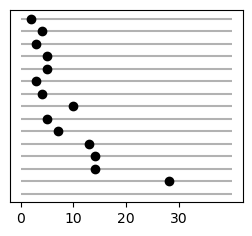

In [ ]:
#max_performance, highrank = sort_eval_values_at_mff(eval_en)
highrank = refcor_highrank_all[::-1]
# only distances that are in the highrank list
eval_en["distance"] = eval_en["distance"].astype(str)
refcor_highrank_en = [str(x) for x in refcor_highrank_all]
eval_en = eval_en[eval_en["distance"].isin(refcor_highrank_en)]
eval_en["highrank"] = eval_en["distance"].apply(lambda x: highrank.index(x))

# de
eval_de["distance"] = eval_de["distance"].astype(str)
refcor_highrank_de = [str(x) for x in refcor_highrank_all]
eval_de = eval_de[eval_de["distance"].isin(refcor_highrank_de)]
eval_de["highrank"] = eval_de["distance"].apply(lambda x: highrank.index(x))

# fr
eval_fr["distance"] = eval_fr["distance"].astype(str)
refcor_highrank_fr = [str(x) for x in refcor_highrank_all]
eval_fr = eval_fr[eval_fr["distance"].isin(refcor_highrank_fr)]
eval_fr["highrank"] = eval_fr["distance"].apply(lambda x: highrank.index(x))

# ice
eval_ice["distance"] = eval_ice["distance"].astype(str)
refcor_highrank_ice = [str(x) for x in refcor_highrank_all]
eval_ice = eval_ice[eval_ice["distance"].isin(refcor_highrank_ice)]
eval_ice["highrank"] = eval_ice["distance"].apply(lambda x: highrank.index(x))

plt.figure(figsize=(3,2.5))
scatter_for_eval(eval_fr, 5000, "cl_error", len(refcor_highrank_all)+1, max_x=40, yticks=True, xticks_list=[0, 10, 20, 30], colour="black")
#scatter_for_eval(eval_fr, 100, "simple_score", len(refcor_highrank_all)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="green")
#scatter_for_eval(eval_de, 1000, "ari", len(refcor_highrank_de)+1, 1, yticks=True, xticks_list=[0.2, 0.4, 0.6, 0.8], colour="red")
#scatter_for_eval(eval_en, 1000, "ari", len(refcor_highrank_en)+1, 1, yticks=True, xticks_list=[0.2, 0.4, 0.6, 0.8], colour="blue")
#scatter_for_eval(eval_ice, 100, "simple_score", len(refcor_highrank_all)+1, 4, yticks=True, xticks_list=[0, 1, 2, 3], colour="orange")
plt.show()

In [94]:
ari_best = eval_ice[eval_ice["step"].isin([100, 1000, 5000])].sort_values(by=["ari"], ascending=False)[eval_ice["ari"]>0.75]
ari_best

C:\Users\N\AppData\Local\Temp\ipykernel_7592\2816321646.py:1: UserWarning: Boolean Series key will be reindexed to match DataFrame index.
  ari_best = eval_ice[eval_ice["step"].isin([100, 1000, 5000])].sort_values(by=["ari"], ascending=False)[eval_ice["ari"]>0.75]


,distance,feature,step,simple_score,ari,cl_error,cl_correct_pc,primary_acc,secondary_acc,either_acc,both_acc,language,highrank
209,Cosine Delta,lex_1_rel,1000.0,3.154874,1.000000,0.0,1.000000,0.984848,0.848485,1.000000,0.833333,Icelandic,15
221,Cosine Delta,lex_1_rel,5000.0,3.531548,1.000000,0.0,1.000000,0.969697,0.833333,1.000000,0.803030,Icelandic,15
93,Burrows' Delta,lex_1_rel,1000.0,1.987808,0.918220,1.0,0.984848,0.878788,0.621212,0.924242,0.575758,Icelandic,14
337,Eder's Delta,lex_1_rel,5000.0,1.829469,0.881872,2.0,0.969697,0.893939,0.590909,0.924242,0.560606,Icelandic,13
743,Linear Delta,lex_1_rel,5000.0,1.679477,0.881872,2.0,0.969697,0.787879,0.530303,0.893939,0.424242,Icelandic,11
279,Eder's Simple Delta,lex_1_rel,5000.0,1.844935,0.881872,2.0,0.969697,0.893939,0.590909,0.924242,0.560606,Icelandic,10
191,Cosine Delta,lex_1_rel,100.0,2.585440,0.865238,3.0,0.954545,0.893939,0.666667,0.954545,0.606061,Icelandic,15
395,Entropy,lex_1_rel,5000.0,1.848413,0.844057,2.0,0.969697,0.742424,0.545455,0.848485,0.439394,Icelandic,1
35,Quadratic Delta,lex_1_rel,1000.0,1.836566,0.839794,3.0,0.954545,0.772727,0.515152,0.863636,0.424242,Icelandic,6
105,Burrows' Delta,lex_1_rel,5000.0,1.755020,0.818123,3.0,0.954545,0.909091,0.575758,0.939394,0.545455,Icelandic,14


In [68]:
# calculate mean score across simple_score, ari, cl_error, rank accordingly

def calculate_mean_scores_and_ranks(df):
    mean_scores = df.groupby(["distance"]).agg({
        "simple_score": "mean",
        "cl_error": "mean",
        "ari": "mean"
    }).reset_index()
    
    mean_scores["rank1"] = mean_scores["simple_score"].rank(ascending=False)
    mean_scores["rank2"] = mean_scores["cl_error"].rank(ascending=True)
    mean_scores["rank3"] = mean_scores["ari"].rank(ascending=False)
    
    mean_scores["mean_rank"] = mean_scores[["rank1", "rank2", "rank3"]].mean(axis=1)
    mean_scores["median_rank"] = mean_scores[["rank1", "rank2", "rank3"]].median(axis=1)
    mean_scores["sum_rank"] = mean_scores[["rank1", "rank2", "rank3"]].sum(axis=1)
    
    mean_scores = mean_scores.sort_values(by=["mean_rank"], ascending=True)
    
    return mean_scores

calculate_mean_scores_and_ranks(eval_ice)

,distance,simple_score,cl_error,ari,rank1,rank2,rank3,mean_rank,median_rank,sum_rank
6,Cosine Delta,2.812260,6.103448,0.816084,1.0,1.0,1.0,1.000000,1.0,3.0
7,Eder's Delta,1.795138,7.758621,0.697866,2.0,4.0,3.0,3.000000,3.0,9.0
1,Burrows' Delta,1.765398,7.465517,0.696127,3.0,3.0,4.0,3.333333,3.0,10.0
11,Hoover's P1 Delta,1.653878,6.693878,0.705626,6.0,2.0,2.0,3.333333,2.0,10.0
8,Eder's Simple Delta,1.654074,10.379310,0.631009,5.0,7.0,5.0,5.666667,5.0,17.0
12,Linear Delta,1.605949,10.137931,0.623521,10.0,6.0,6.0,7.333333,6.0,22.0
9,Entropy,1.643380,11.448276,0.583565,7.0,8.0,8.0,7.666667,8.0,23.0
15,Quadratic Delta,1.567740,9.086207,0.611617,11.0,5.0,7.0,7.666667,7.0,23.0
14,Min-Max,1.723429,12.327586,0.551732,4.0,11.0,9.0,8.000000,9.0,24.0
0,Bray-Curtis,1.631652,12.189655,0.545939,8.0,9.0,10.0,9.000000,9.0,27.0


In [95]:
# for plotting purposes
import matplotlib.pyplot as plt
import seaborn as sns

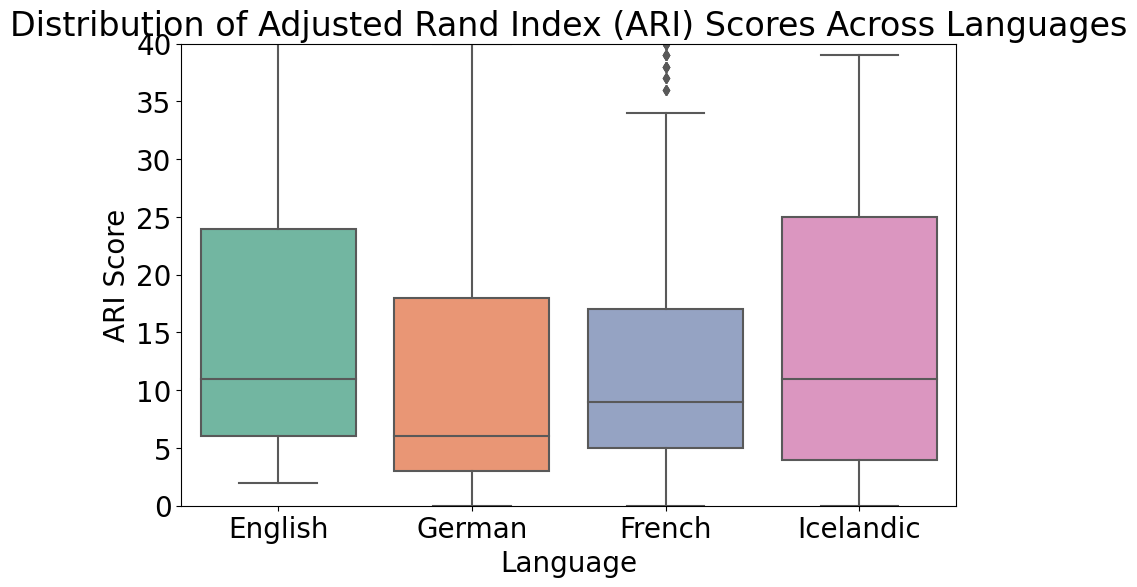

In [296]:
# plot distribution of ari scores across all languages and distances
plt.figure(figsize=(10,6))
sns.boxplot(x="language", y="cl_error", data=eval_all, palette="Set2")
plt.title("Distribution of Adjusted Rand Index (ARI) Scores Across Languages")
plt.xlabel("Language")
plt.ylabel("ARI Score")
plt.ylim(0, 40)
plt.show()

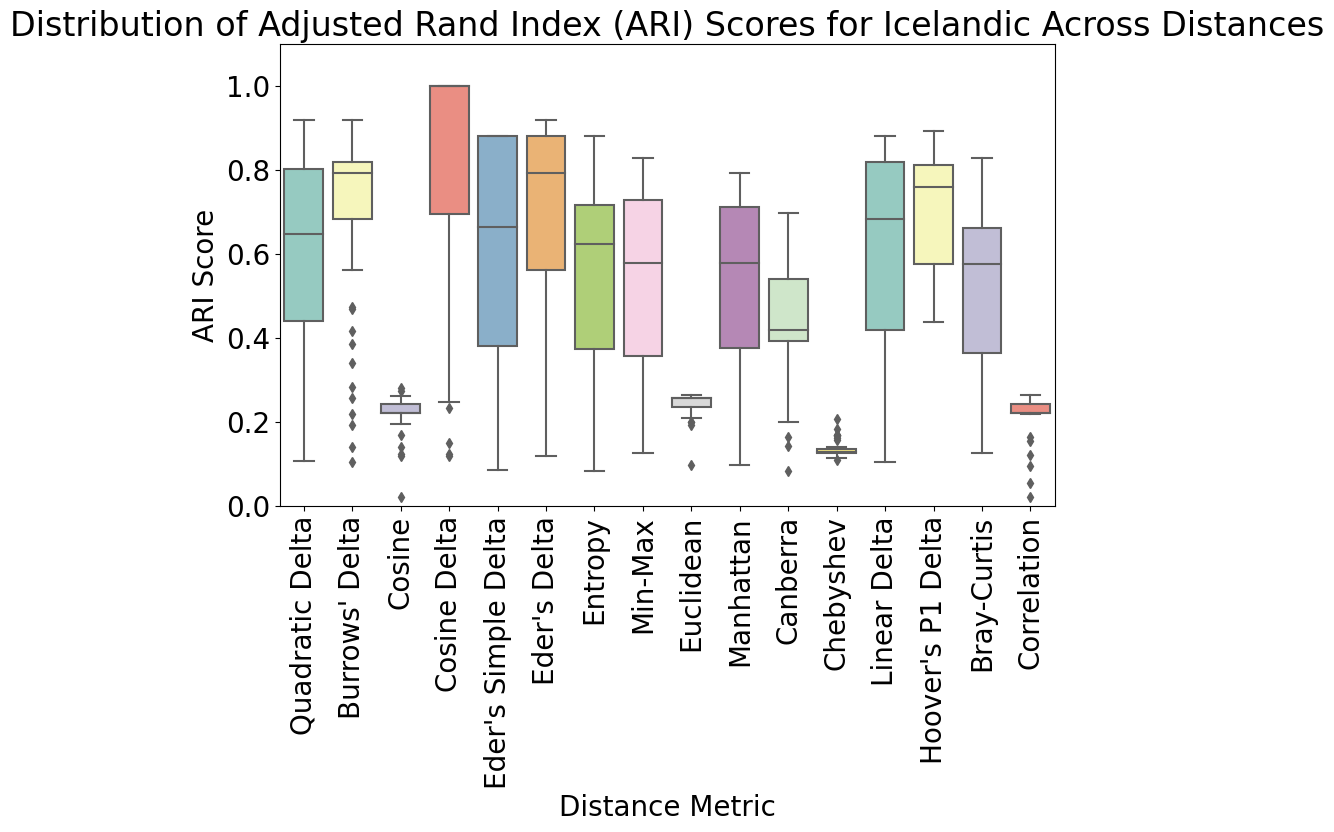

In [111]:
#plot distribution of ari for icelandic
plt.figure(figsize=(10,6))
sns.boxplot(x="distance", y="ari", data=eval_ice, palette="Set3")
plt.title("Distribution of Adjusted Rand Index (ARI) Scores for Icelandic Across Distances")
plt.xlabel("Distance Metric")
plt.ylabel("ARI Score")
plt.ylim(0, 1.1)
plt.xticks(rotation=90)
plt.show()

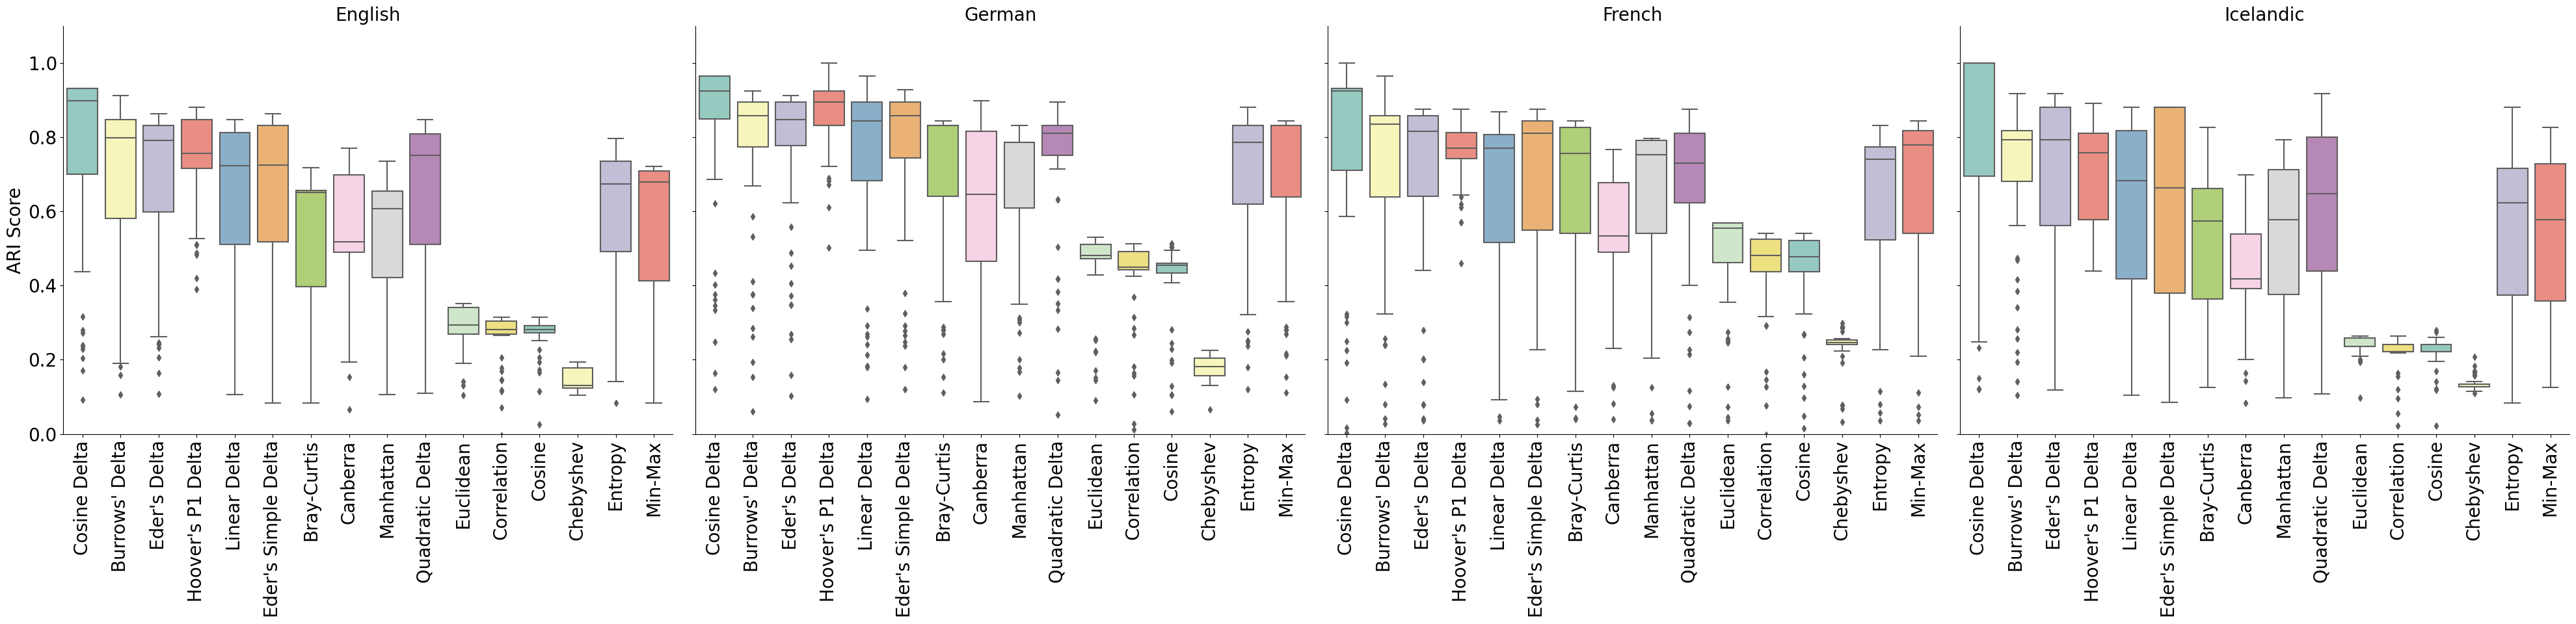

In [ ]:
# facet grid
# 3 subplots 
g = sns.FacetGrid(eval_all, col="language", col_wrap=4, height=10, sharey=True)
g.map(sns.boxplot, "distance", "ari", order=refcor_highrank_all, palette="Set3")
g.set_titles("{col_name}")
g.set_axis_labels("", "ARI Score")
g.set(ylim=(0, 1.1))
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.tight_layout()
plt.show()


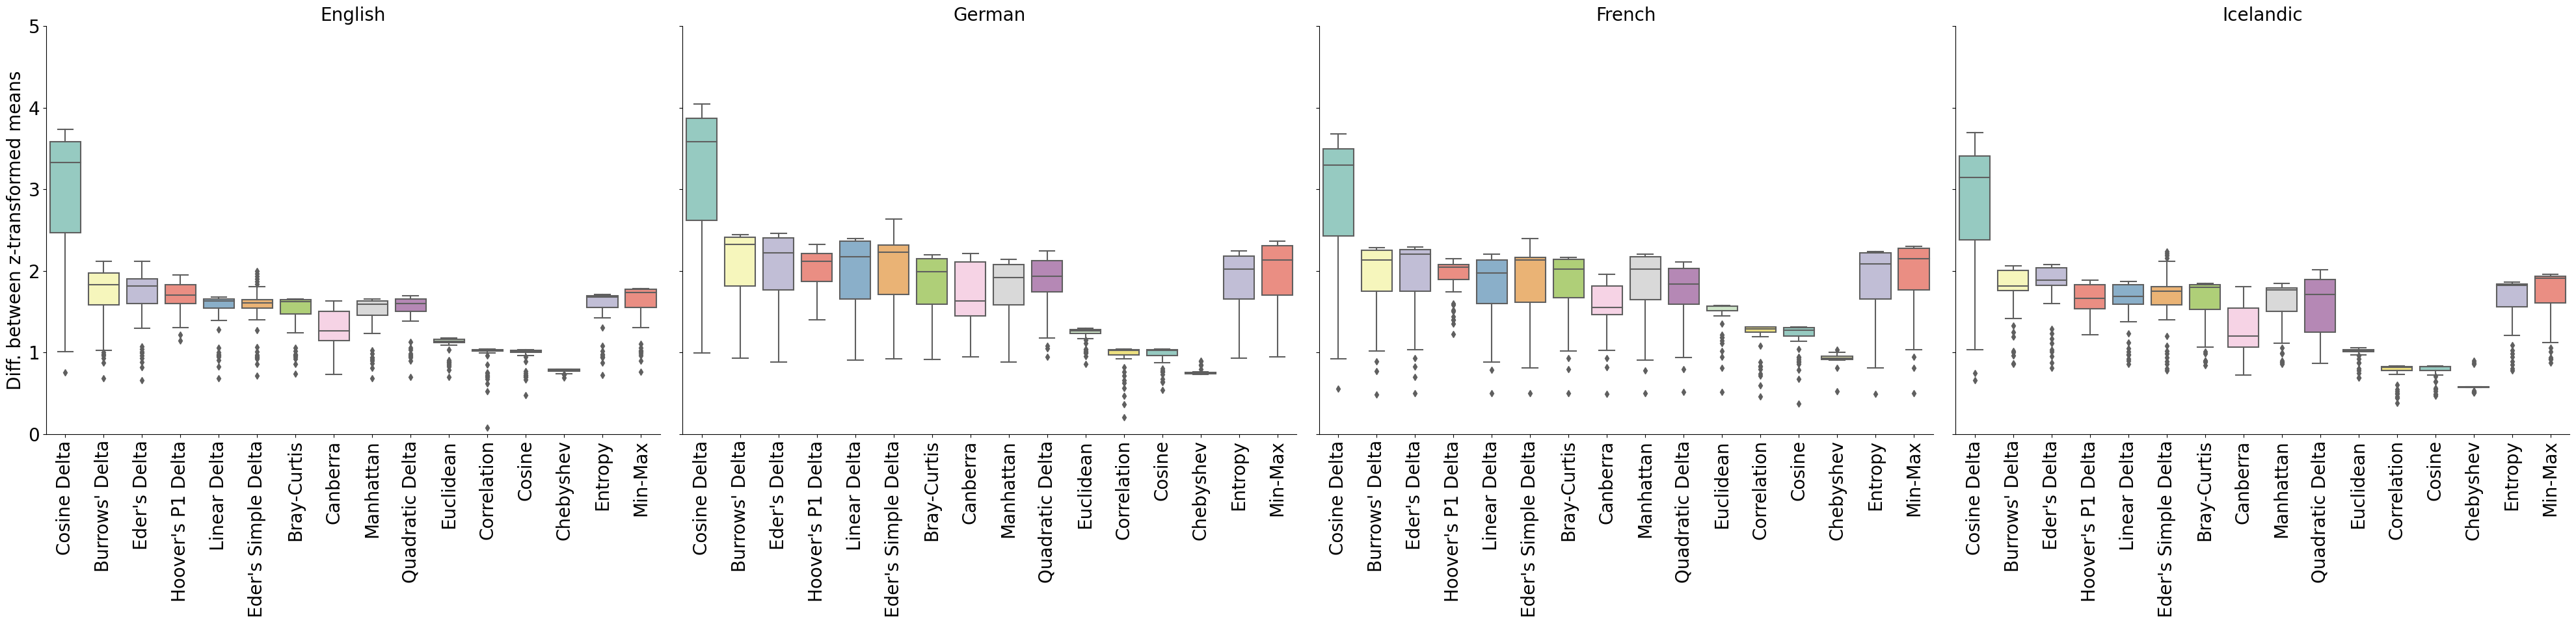

In [241]:
# facet grid
g = sns.FacetGrid(eval_all, col="language", col_wrap=4, height=10, sharey=True)
g.map(sns.boxplot, "distance", "simple_score", order=refcor_highrank_all, palette="Set3")
g.set_titles("{col_name}")
g.set_axis_labels("", "Diff. between z-transformed means")
g.set(ylim=(0, 5))
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.tight_layout()
plt.show()


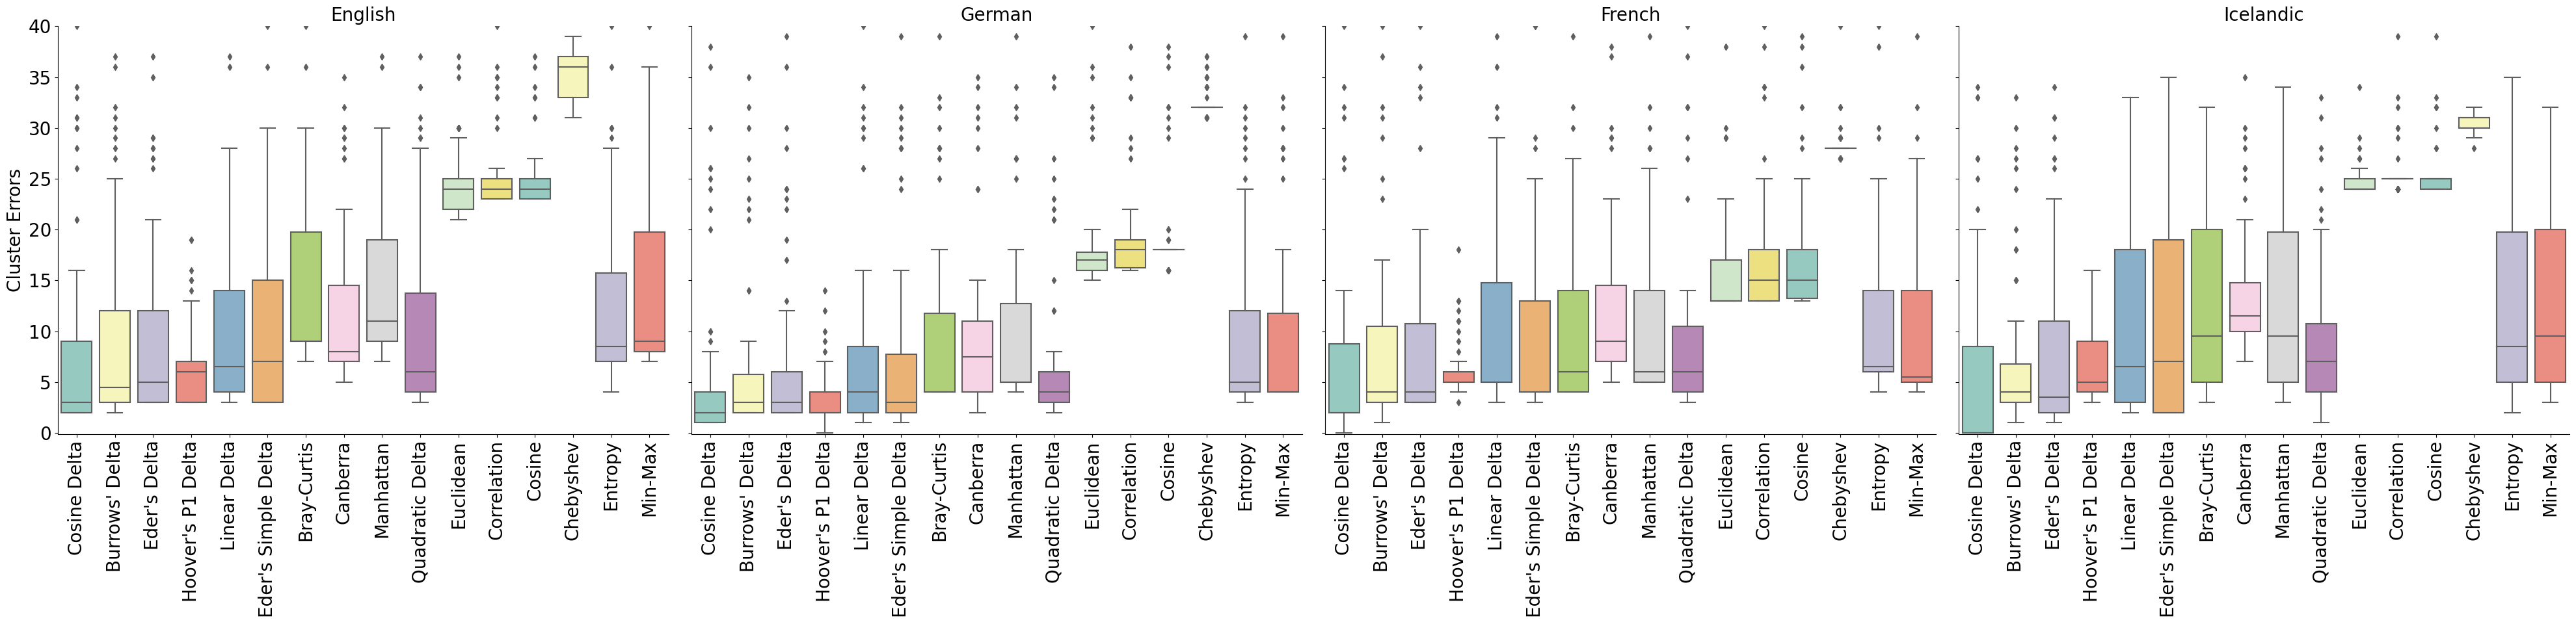

In [243]:
# facet grid
g = sns.FacetGrid(eval_all, col="language", col_wrap=4, height=10, sharey=True)
g.map(sns.boxplot, "distance", "cl_error", order=refcor_highrank_all, palette="Set3")
g.set_titles("{col_name}")
g.set_axis_labels("", "Cluster Errors")
g.set(ylim=(-0.1, 40))
for ax in g.axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)
plt.tight_layout()
plt.show()


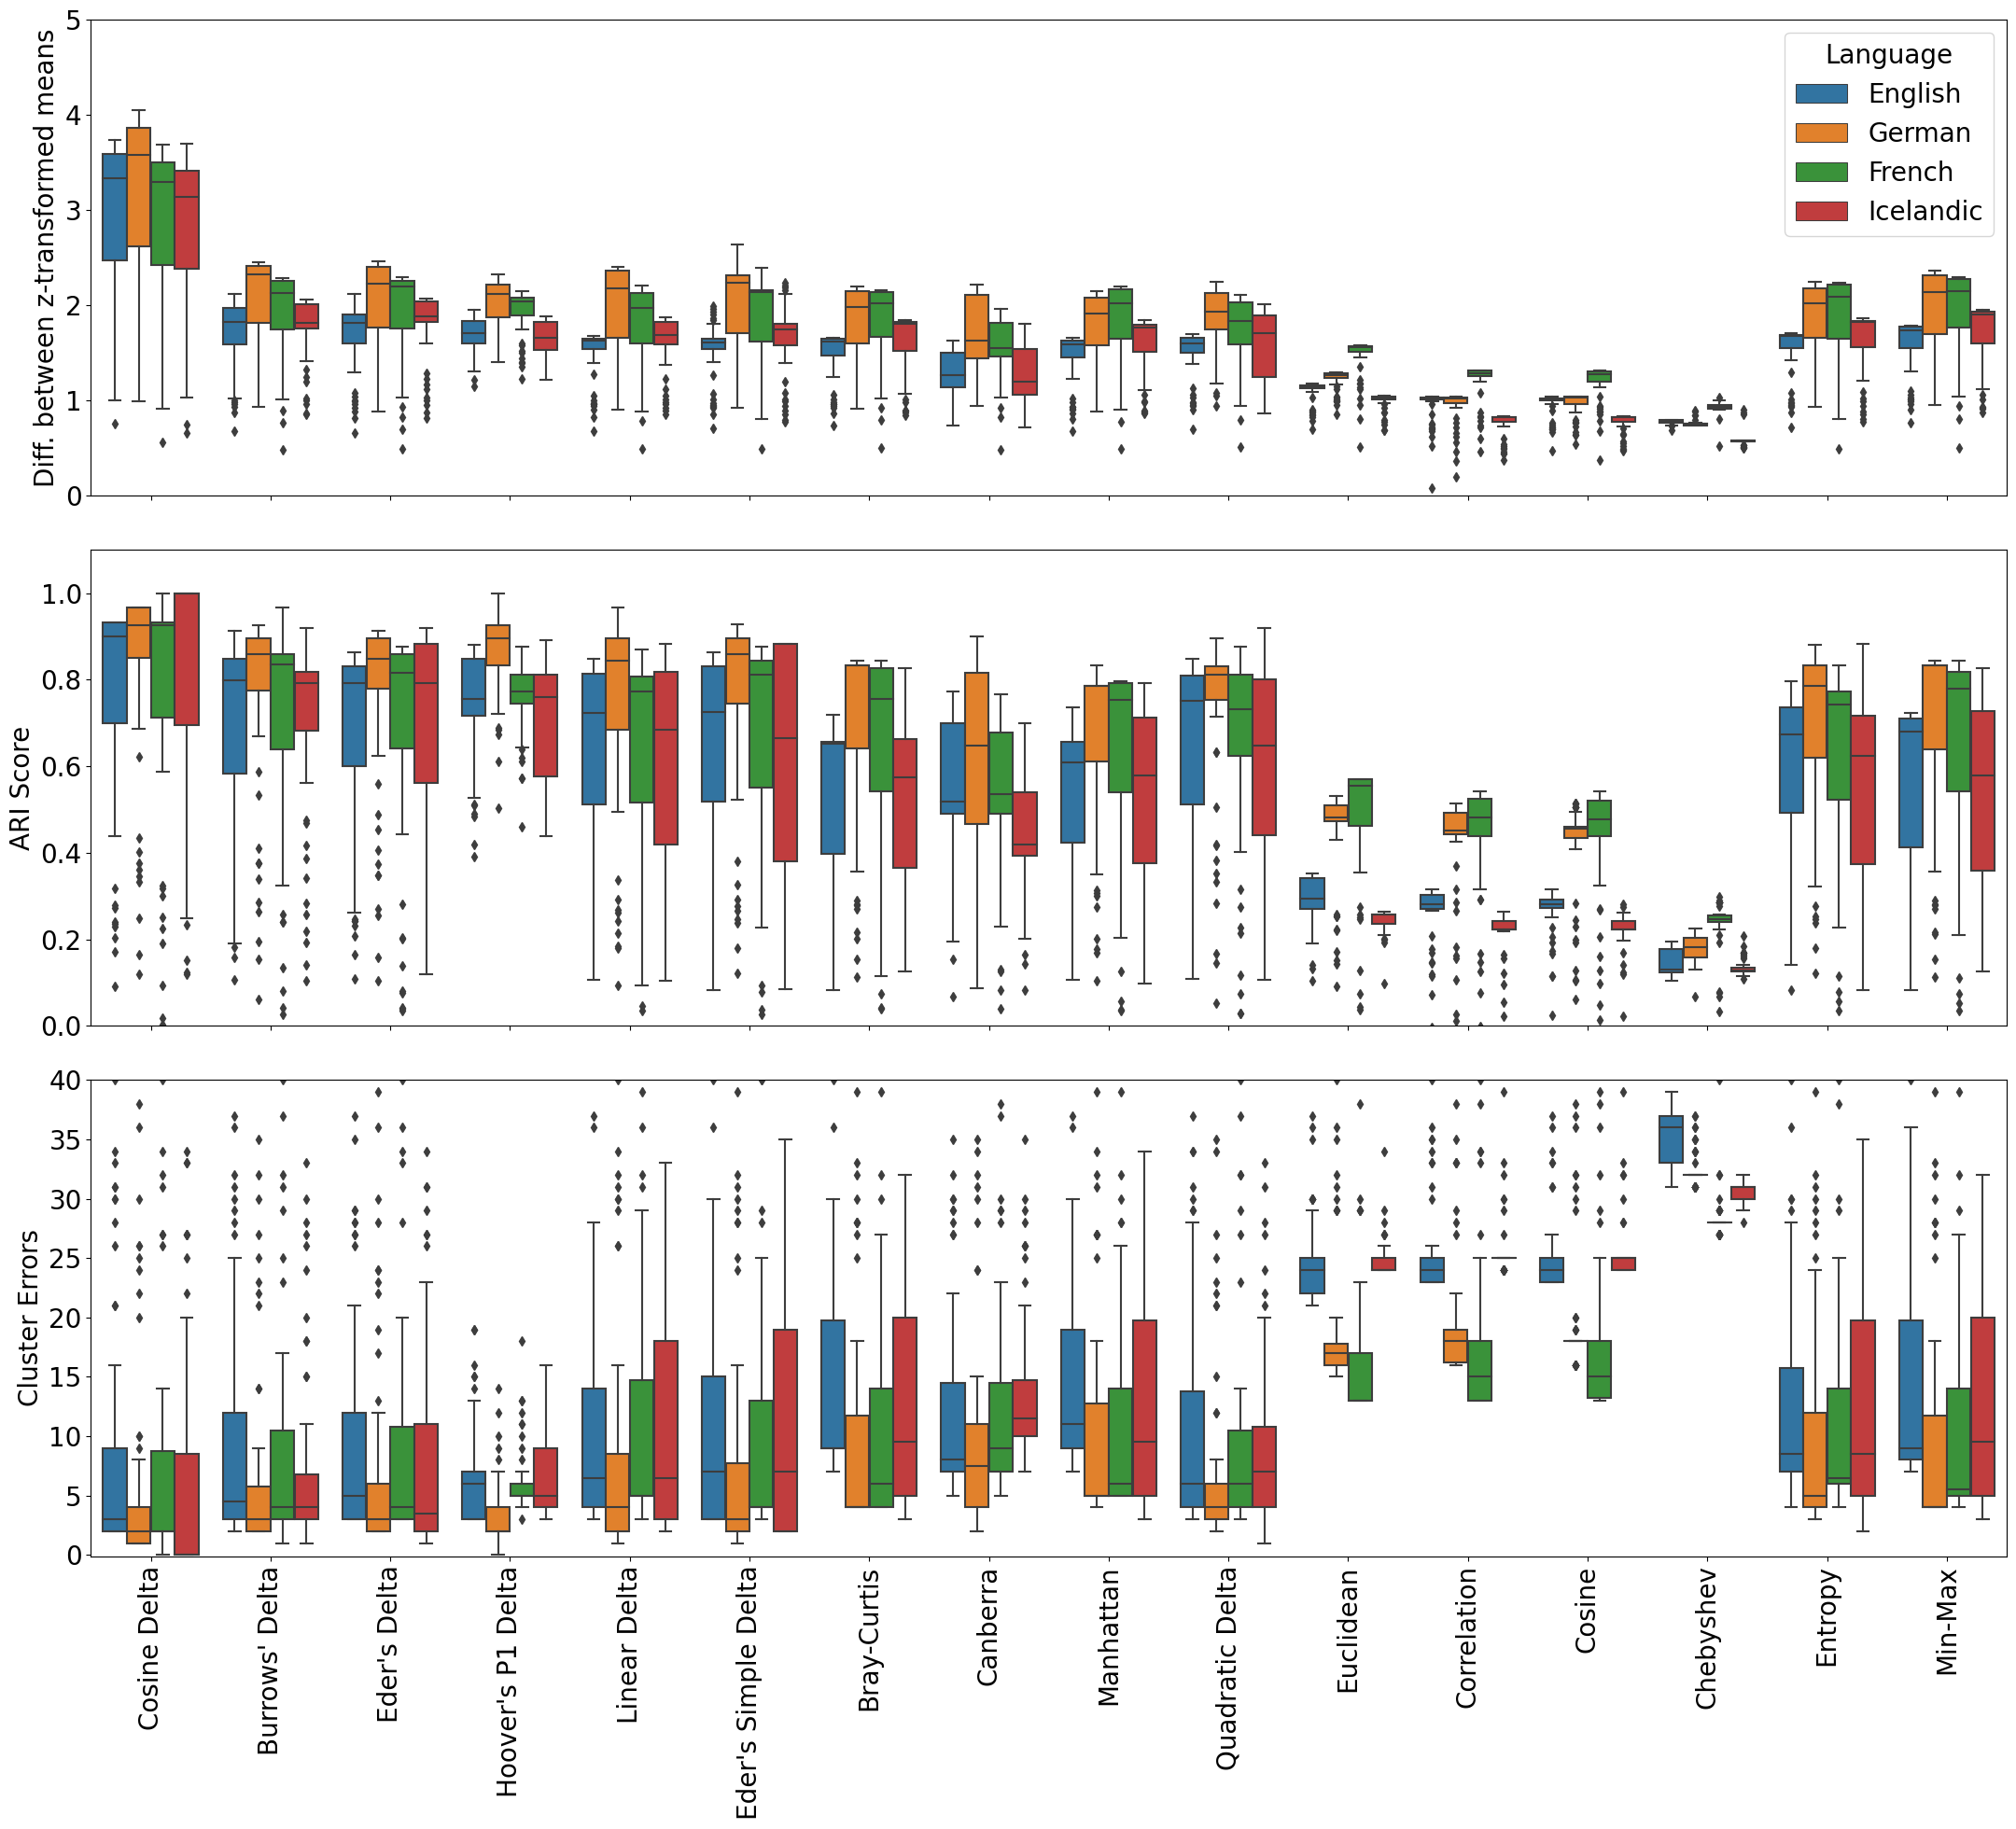

In [286]:
# trhee of the above into one plot
fig, axes = plt.subplots(figsize=(22, 20), nrows=3, ncols=1)
# Simple Score
sns.boxplot(x="distance", y="simple_score", hue="language", data=eval_all, order=refcor_highrank_all, ax=axes[0])
axes[0].set_title("")
axes[0].set_xlabel("")
axes[0].set_ylabel("Diff. between z-transformed means")
axes[0].set_ylim(0, 5)
axes[0].legend(title="Language")

# disable x-ticks
axes[0].set_xticklabels([])
# ARI
sns.boxplot(x="distance", y="ari", hue="language", data=eval_all, order=refcor_highrank_all, ax=axes[1])
axes[1].set_title("")
axes[1].set_xlabel("")
axes[1].set_ylabel("ARI Score")
axes[1].set_ylim(0, 1.1)
axes[1].legend_.remove()
axes[1].set_xticklabels([])

# Cluster Errors
sns.boxplot(x="distance", y="cl_error", hue="language", data=eval_all, order=refcor_highrank_all, ax=axes[2])
axes[2].set_title("")
axes[2].set_xlabel("")
axes[2].set_ylabel("Cluster Errors")
axes[2].set_ylim(-0.1, 40)
axes[2].legend_.remove()
for label in axes[2].get_xticklabels():
    label.set_rotation(90)

plt.tight_layout()
plt.show()

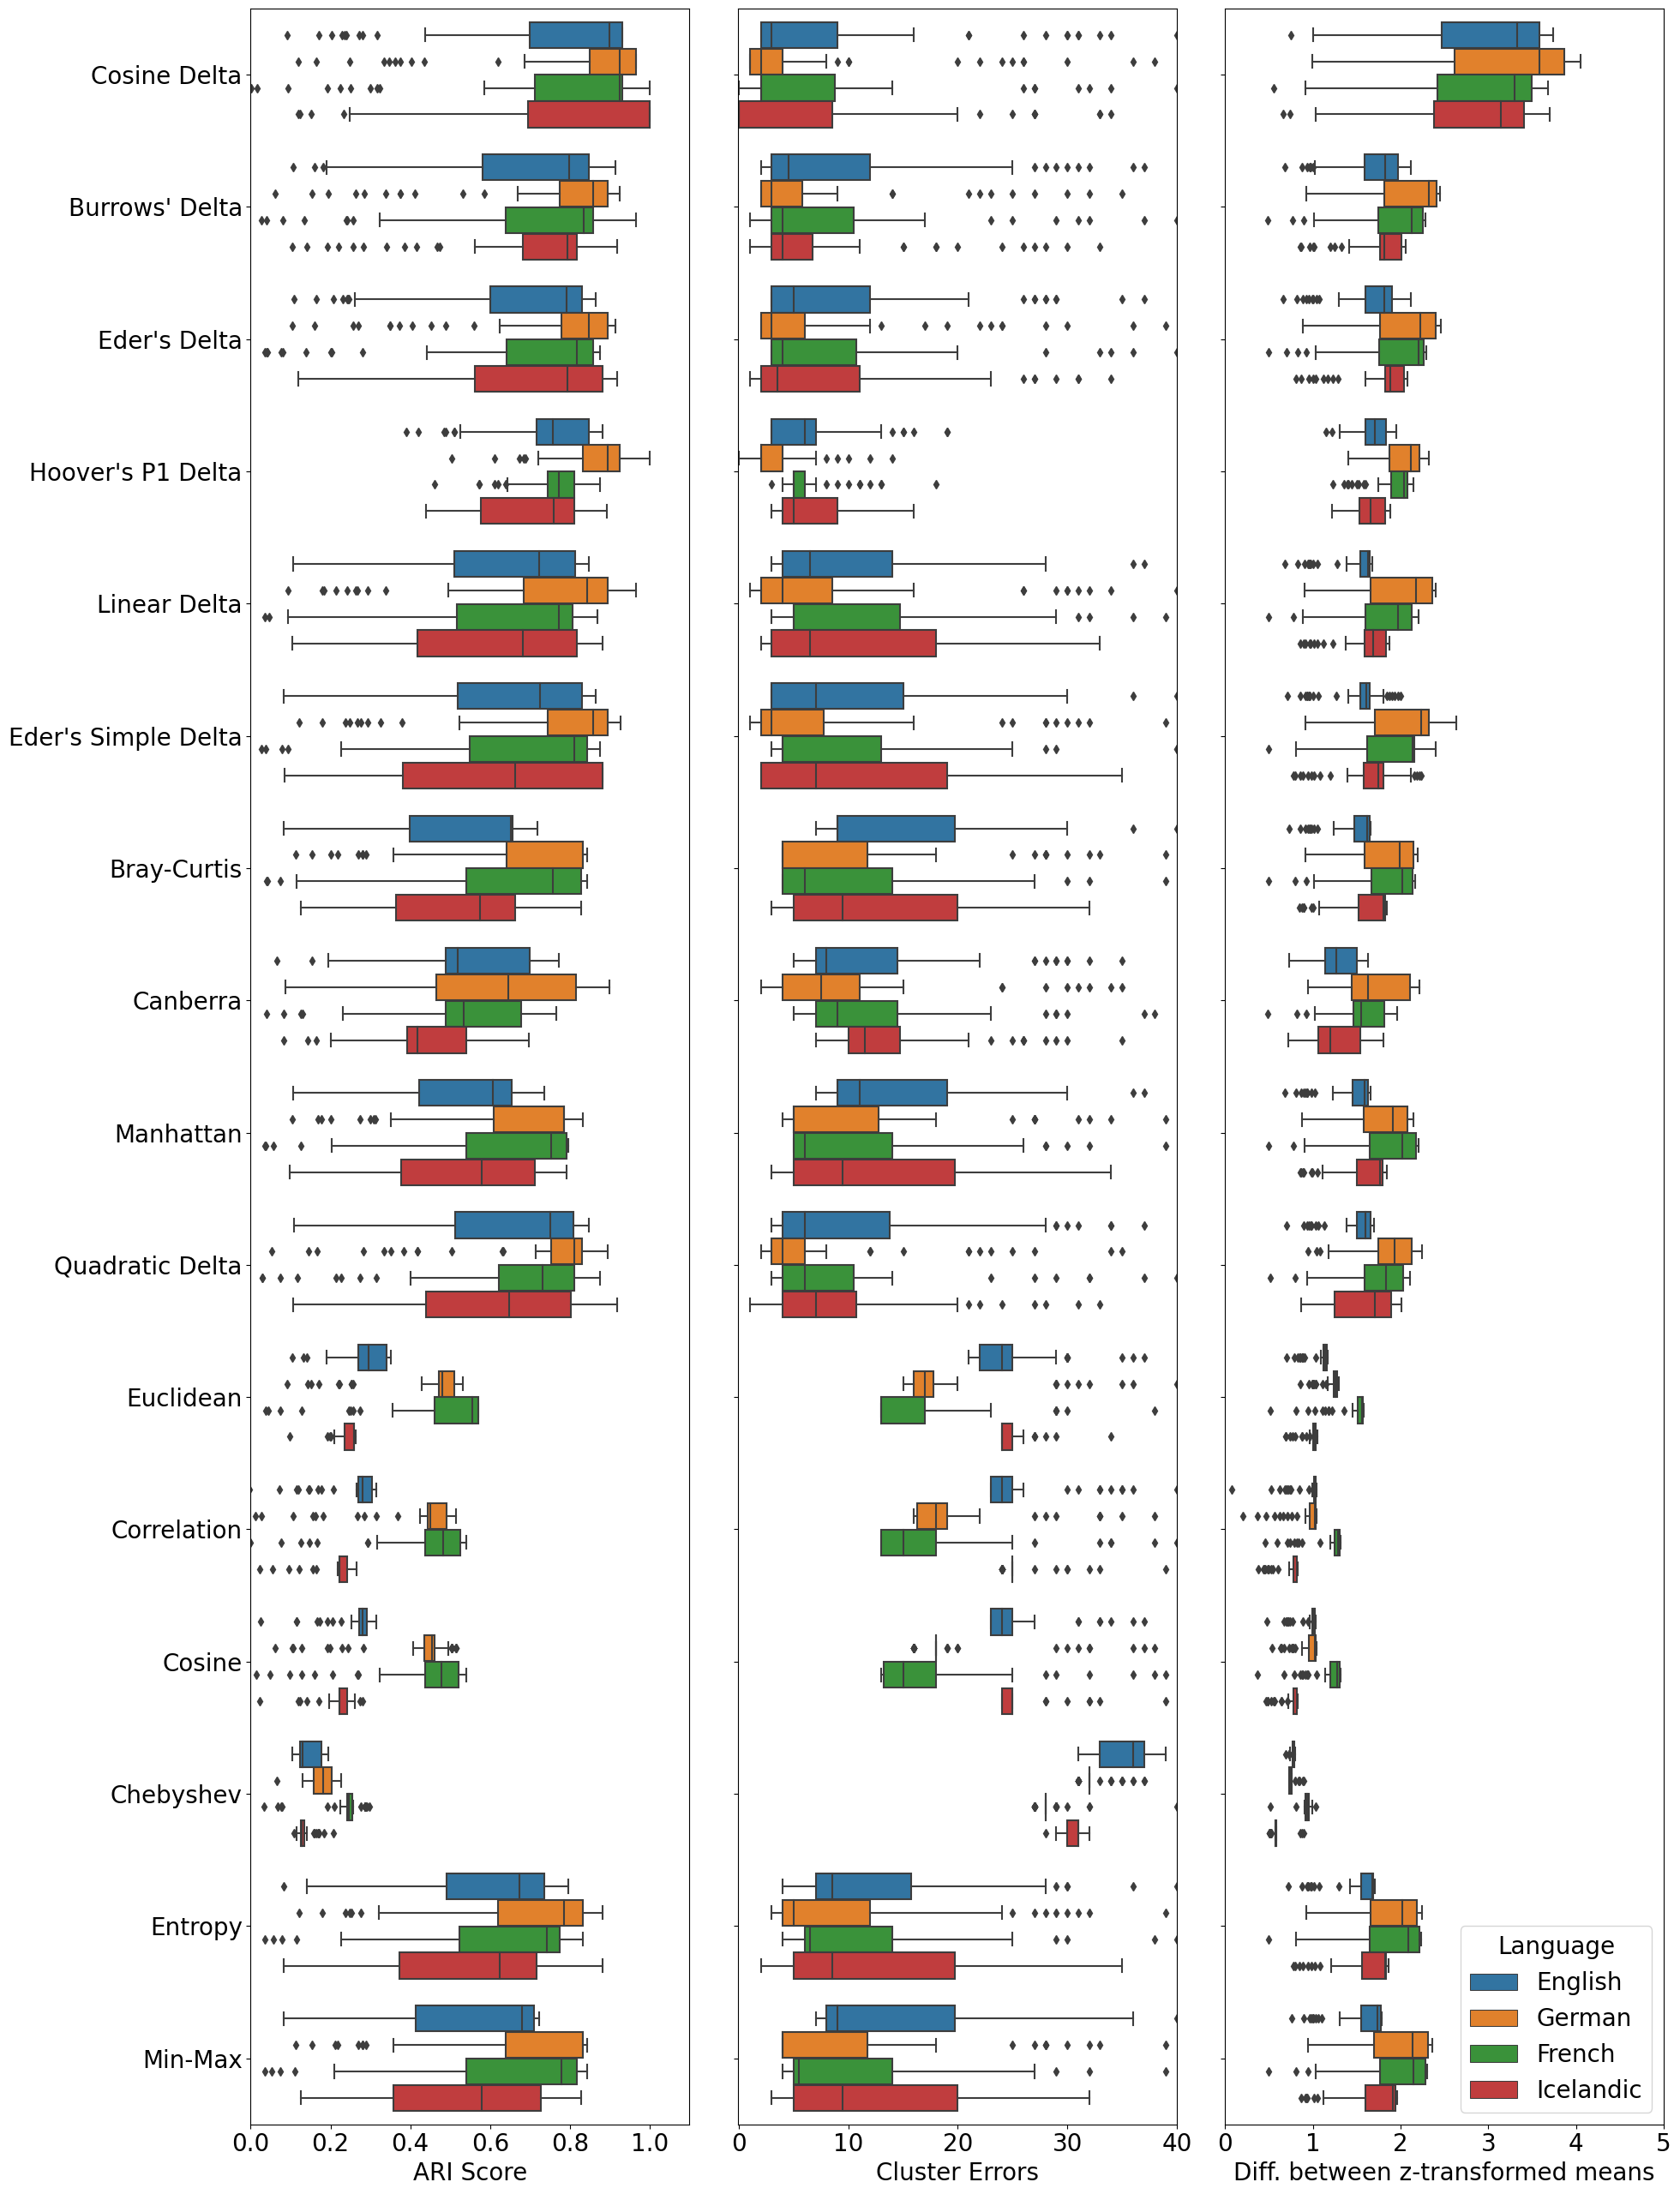

In [332]:
fig, axes = plt.subplots(figsize=(20, 26), nrows=1, ncols=3)



# ARI
sns.boxplot(
    x="ari", y="distance",
    hue="language",
    data=eval_all,
    order=refcor_highrank_all,
    ax=axes[0]
)
axes[0].set_xlabel("ARI Score")
axes[0].set_ylabel("")
axes[0].set_xlim(0, 1.1)
axes[0].legend_.remove()

# Cluster Errors
sns.boxplot(
    x="cl_error", y="distance",
    hue="language",
    data=eval_all,
    order=refcor_highrank_all,
    ax=axes[1]
)
axes[1].set_xlabel("Cluster Errors")
axes[1].set_ylabel("")
axes[1].set_xlim(-0.1, 40)
axes[1].legend_.remove()
axes[1].set_yticklabels([])

# Simple Score
sns.boxplot(
    x="simple_score", y="distance",
    hue="language",
    data=eval_all,
    order=refcor_highrank_all,
    ax=axes[2]
)
axes[2].set_xlabel("Diff. between z-transformed means")
axes[2].set_ylabel("")
axes[2].set_xlim(0, 5)
axes[2].legend(title="Language")
axes[2].set_yticklabels([])

plt.tight_layout()
plt.show()


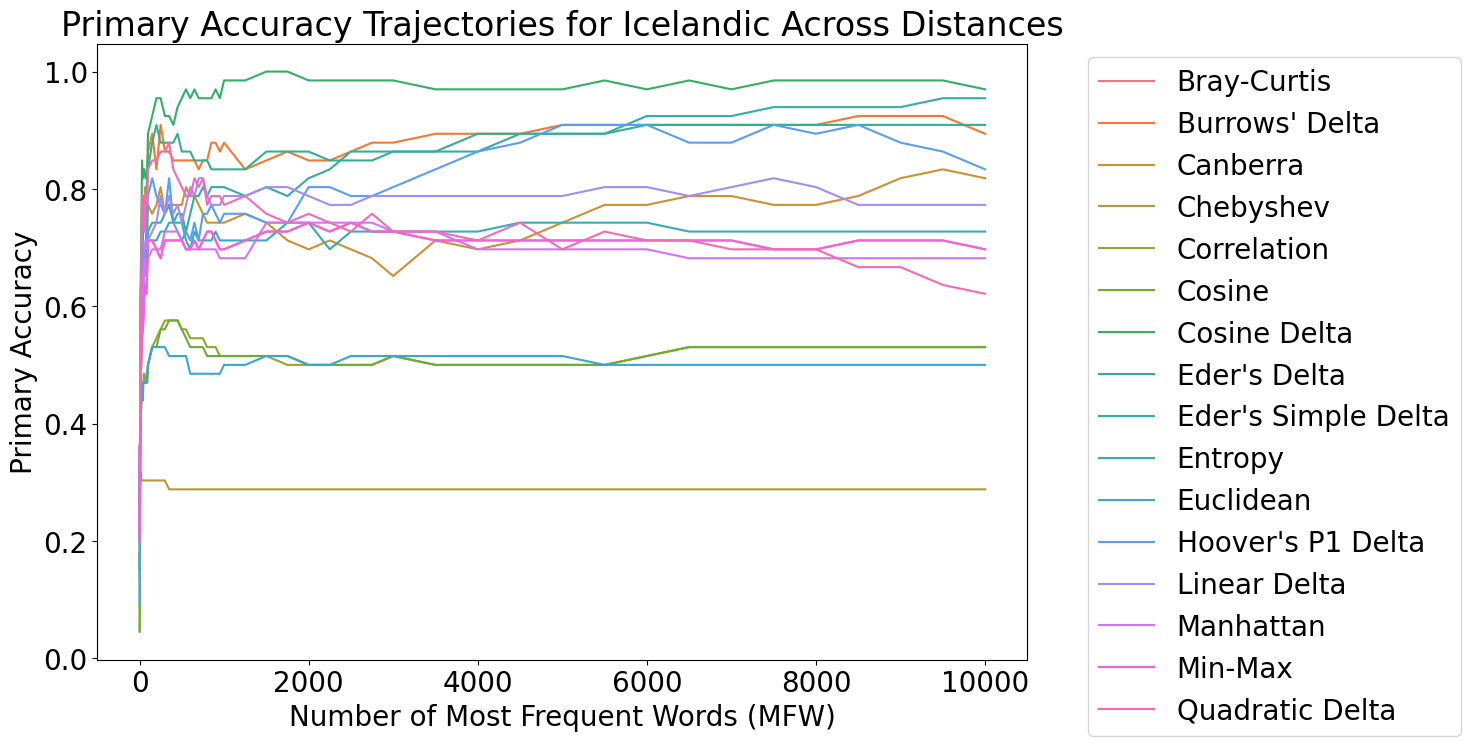

In [124]:
# plot trajectories for icelandic
plt.figure(figsize=(12,8))
sns.lineplot(x="step", y="primary_acc", hue
="distance", data=eval_ice.sort_values(by=["distance"]))
plt.title("Primary Accuracy Trajectories for Icelandic Across Distances")
plt.xlabel("Number of Most Frequent Words (MFW)")
plt.ylabel("Primary Accuracy")
plt.legend(bbox_to_anchor=(1.05, 1), loc='upper left')

plt.show()

In [132]:
eval_ice

,distance,feature,step,simple_score,ari,cl_error,cl_correct_pc,primary_acc,secondary_acc,either_acc,both_acc,language,highrank
0,Quadratic Delta,lex_1_rel,2.0,0.869044,0.107251,33.0,0.500000,0.196970,0.166667,0.318182,0.045455,Icelandic,6
1,Quadratic Delta,lex_1_rel,3.0,0.886319,0.212280,28.0,0.575758,0.287879,0.196970,0.409091,0.075758,Icelandic,6
2,Quadratic Delta,lex_1_rel,4.0,1.009910,0.149284,31.0,0.530303,0.287879,0.166667,0.409091,0.045455,Icelandic,6
3,Quadratic Delta,lex_1_rel,5.0,1.033841,0.236577,27.0,0.590909,0.318182,0.151515,0.424242,0.045455,Icelandic,6
4,Quadratic Delta,lex_1_rel,6.0,0.958328,0.258800,24.0,0.636364,0.333333,0.227273,0.454545,0.106061,Icelandic,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
923,Correlation,lex_1_rel,8000.0,0.821508,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
924,Correlation,lex_1_rel,8500.0,0.821568,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
925,Correlation,lex_1_rel,9000.0,0.821643,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
926,Correlation,lex_1_rel,9500.0,0.821711,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4


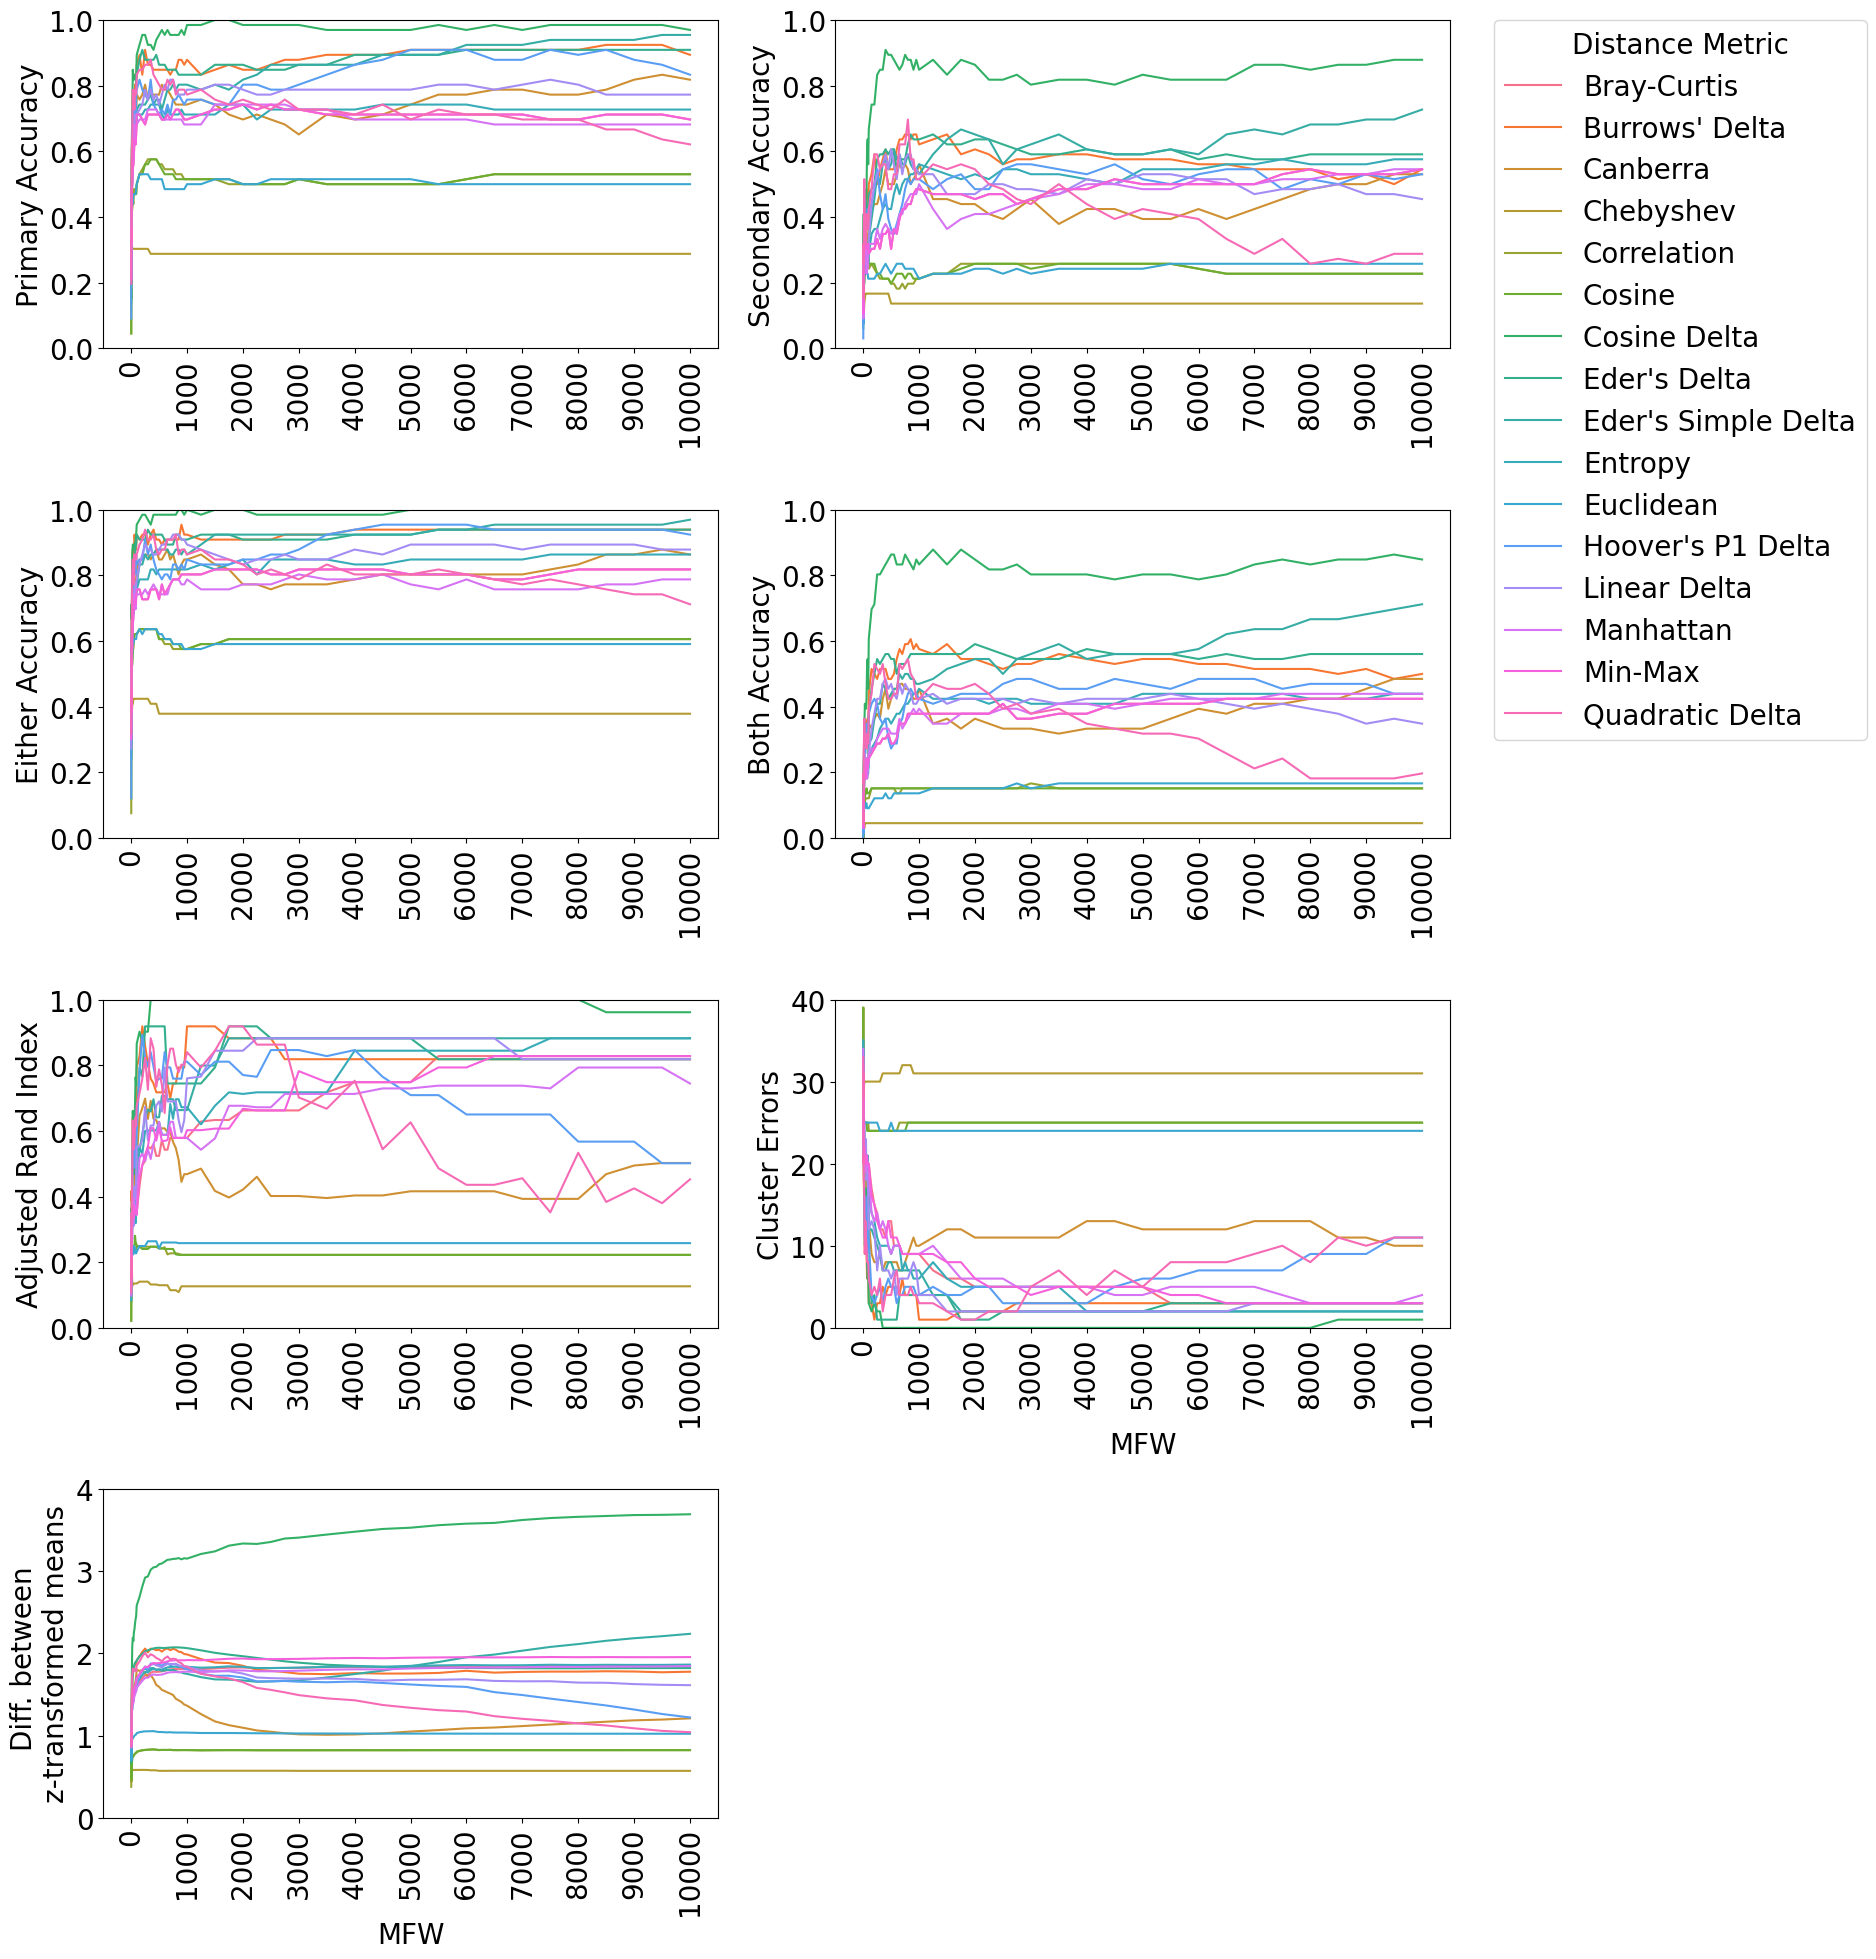

In [219]:
# 4 subplots, primary_acc, secondary_acc, either_acc, both_acc using facegrid
fig, axes = plt.subplots(4, 2, figsize=(15, 20))

sns.lineplot(x="step", y="primary_acc", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[0,0])

axes[0,0].set_xlabel("")
axes[0,0].set_ylabel("Primary Accuracy")
axes[0,0].set_ylim(0, 1)
axes[0,0].legend_.remove()

sns.lineplot(x="step", y="secondary_acc", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[0,1])
axes[0,1].set_xlabel("")
axes[0,1].set_ylabel("Secondary Accuracy")
axes[0,1].set_ylim(0, 1)
axes[0,1].legend_.remove()

sns.lineplot(x="step", y="either_acc", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[1,0])

axes[1,0].set_xlabel("")
axes[1,0].set_ylabel("Either Accuracy")
axes[1,0].set_ylim(0, 1)
axes[1,0].legend_.remove()

sns.lineplot(x="step", y="both_acc", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[1,1])
axes[1,1].set_xlabel("")
axes[1,1].set_ylabel("Both Accuracy")
axes[1,1].set_ylim(0, 1)
axes[1,1].legend_.remove()

sns.lineplot(x="step", y="ari", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[2,0])
axes[2,0].set_xlabel("")
axes[2,0].set_ylabel("Adjusted Rand Index")
axes[2,0].set_ylim(0, 1)
axes[2,0].legend_.remove()
sns.lineplot(x="step", y="cl_error", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[2,1])
axes[2,1].set_xlabel("MFW")
axes[2,1].set_ylabel("Cluster Errors")
axes[2,1].set_ylim(0, 40)
axes[2,1].legend_.remove()

sns.lineplot(x="step", y="simple_score", hue="distance", data=eval_ice.sort_values(by=["distance"]), ax=axes[3,0])
axes[3,0].set_xlabel("MFW")
axes[3,0].set_ylabel("Diff. between \nz-transformed means")
axes[3,0].set_ylim(0, 4)
axes[3,0].legend_.remove()

# last one empty
axes[3,1].axis('off')
# Add a single legend to the upper right of the whole plot, avoiding overlap with subplots
handles, labels = axes[0,0].get_legend_handles_labels()

# Set x-ticks at ten intervals from 0 to max
max_step = 10000
x_ticks = np.arange(0, max_step + 10, 1000)
for ax in axes.flatten():
    ax.set_xticks(x_ticks)

for ax in axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

fig.legend(
    handles,
    labels,
    title="Distance Metric",
    loc="lower left",
    bbox_to_anchor=(1.0, 0.6125),
)

fig.subplots_adjust(right=0.95)


plt.tight_layout()
plt.show()

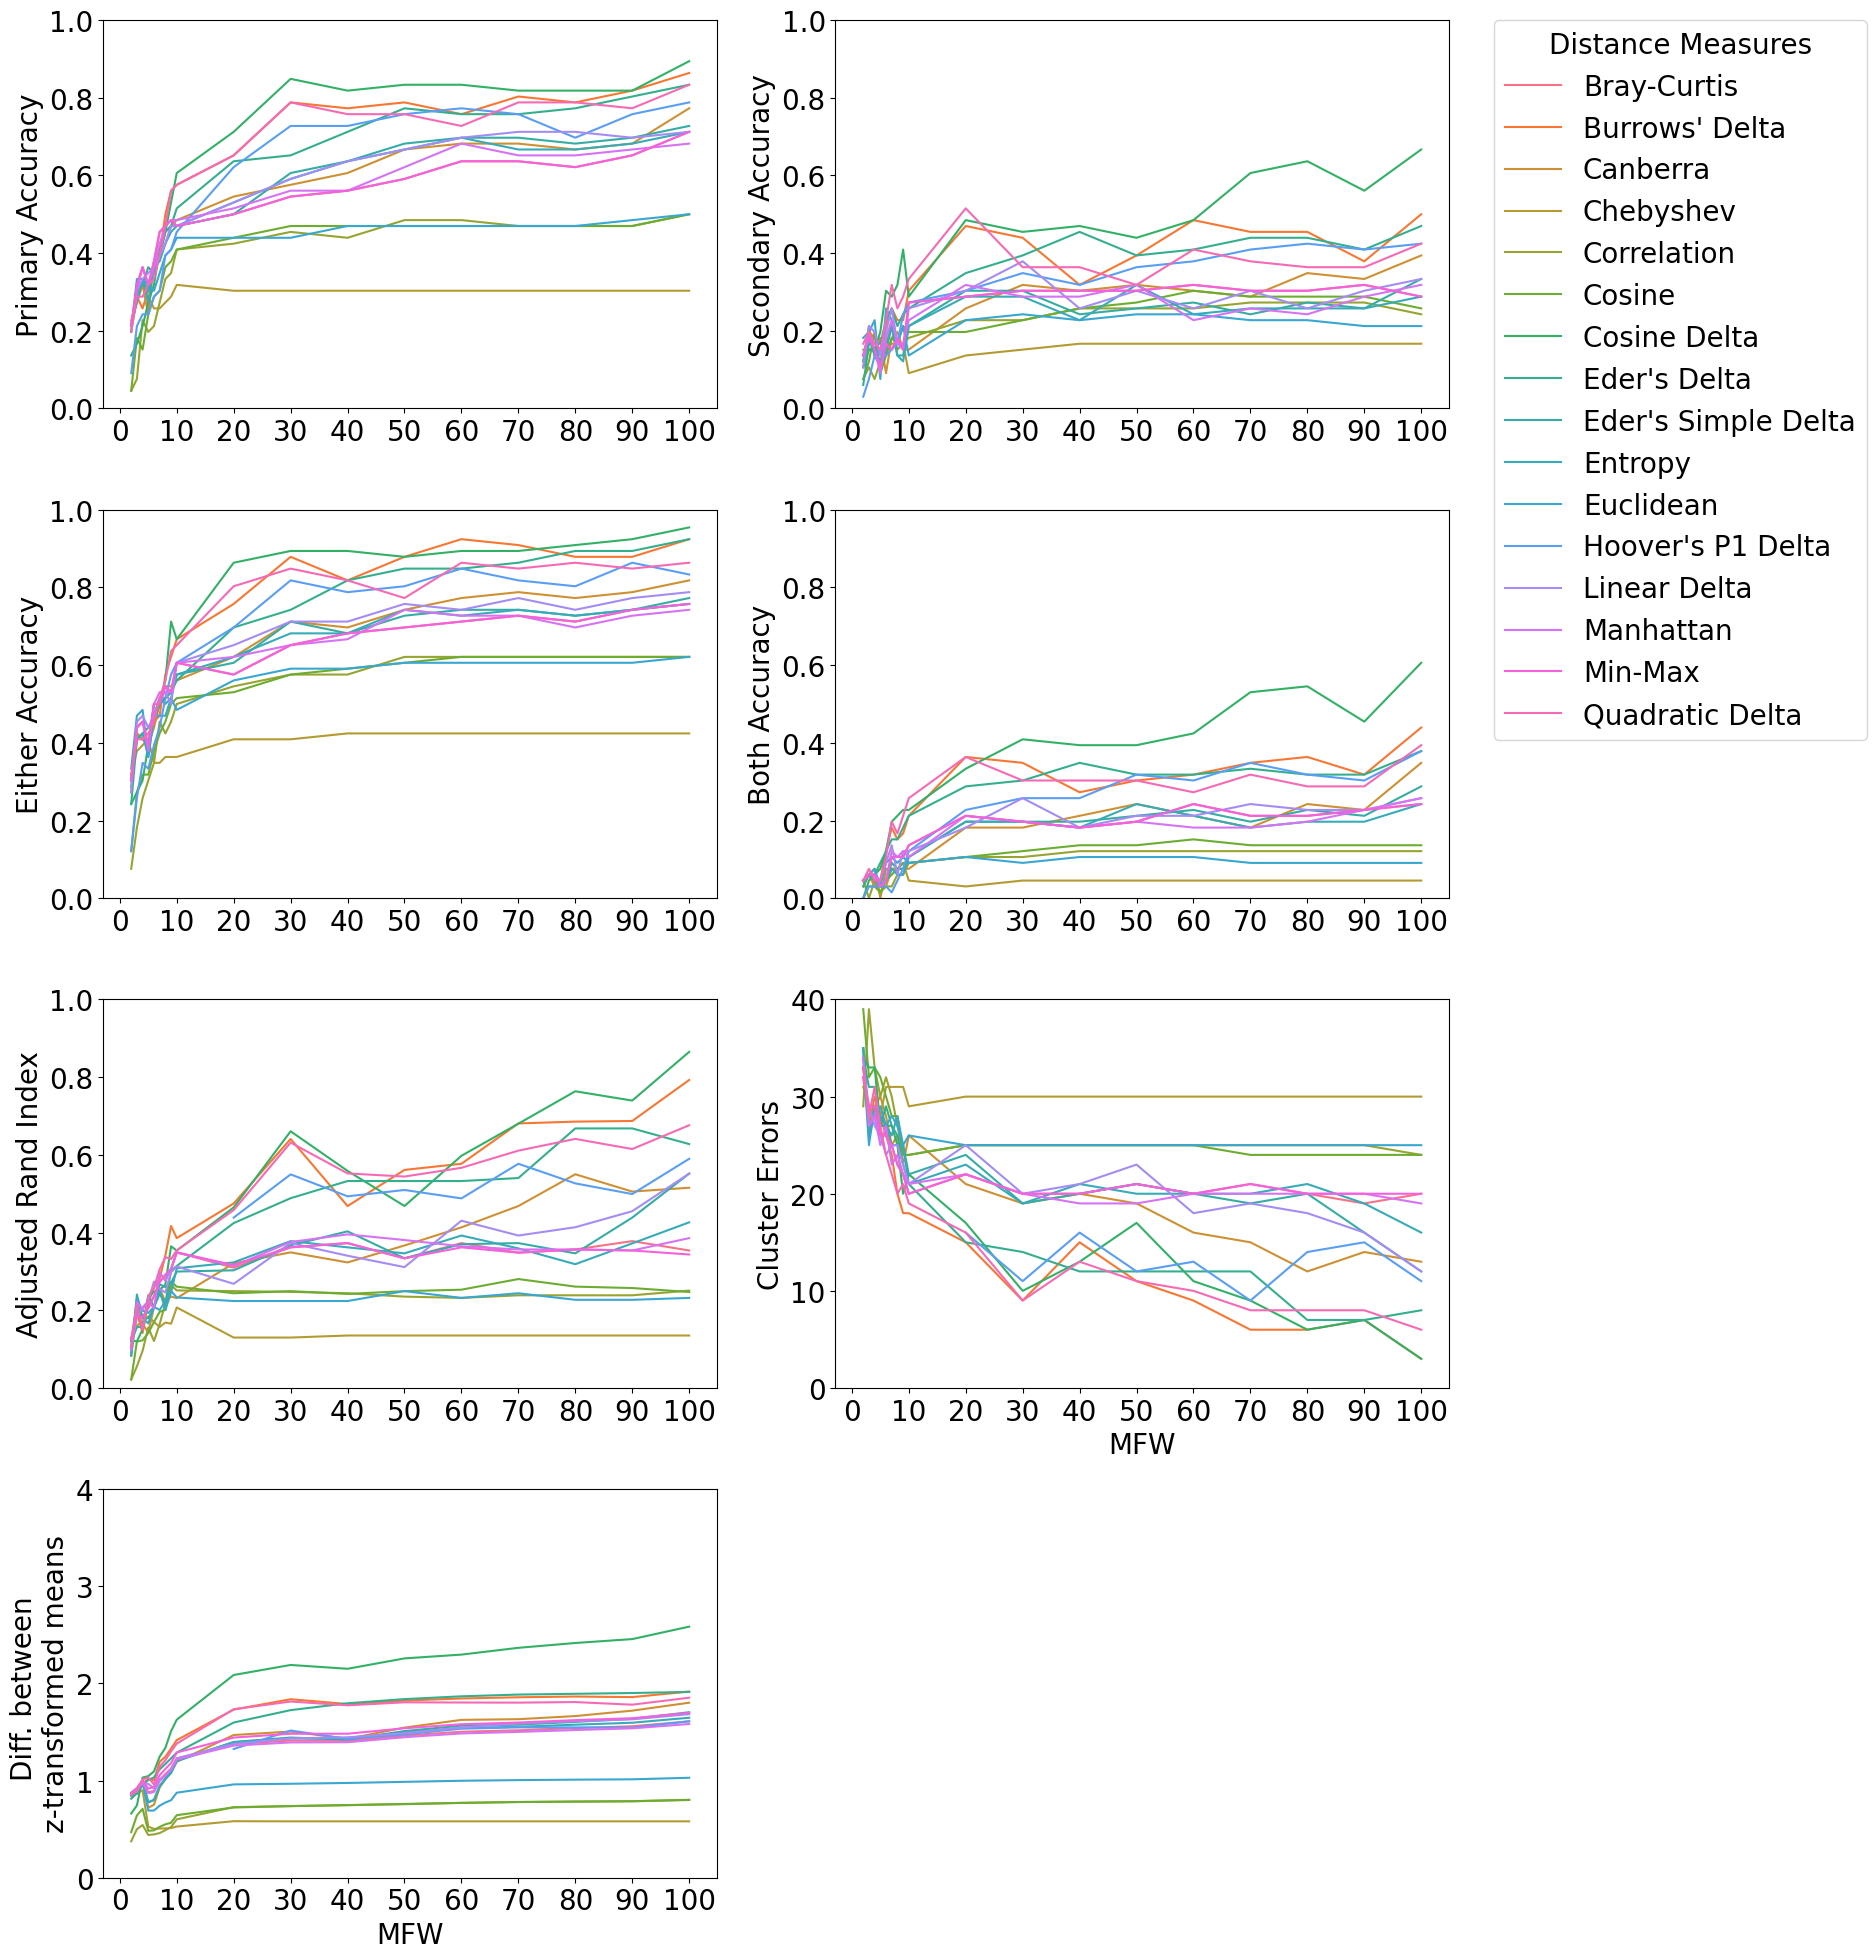

In [192]:
import numpy as np

# 4 subplots, primary_acc, secondary_acc, either_acc, both_acc using facegrid
fig, axes = plt.subplots(4, 2, figsize=(15, 20))

temp_df_eval_ice = eval_ice[eval_ice["step"] <= 100].sort_values(by=["distance"])

sns.lineplot(x="step", y="primary_acc", hue="distance", data=temp_df_eval_ice, ax=axes[0, 0])
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Primary Accuracy")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].legend_.remove()

sns.lineplot(x="step", y="secondary_acc", hue="distance", data=temp_df_eval_ice, ax=axes[0, 1])
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Secondary Accuracy")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend_.remove()

sns.lineplot(x="step", y="either_acc", hue="distance", data=temp_df_eval_ice, ax=axes[1, 0])
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Either Accuracy")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend_.remove()

sns.lineplot(x="step", y="both_acc", hue="distance", data=temp_df_eval_ice, ax=axes[1, 1])
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Both Accuracy")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].legend_.remove()

sns.lineplot(x="step", y="ari", hue="distance", data=temp_df_eval_ice, ax=axes[2, 0])
axes[2, 0].set_xlabel("")
axes[2, 0].set_ylabel("Adjusted Rand Index")
axes[2, 0].set_ylim(0, 1)
axes[2, 0].legend_.remove()

sns.lineplot(x="step", y="cl_error", hue="distance", data=temp_df_eval_ice, ax=axes[2, 1])
axes[2, 1].set_xlabel("MFW")
axes[2, 1].set_ylabel("Cluster Errors")
axes[2, 1].set_ylim(0, 40)
axes[2, 1].legend_.remove()

sns.lineplot(x="step", y="simple_score", hue="distance", data=temp_df_eval_ice, ax=axes[3, 0])
axes[3, 0].set_xlabel("MFW")
axes[3, 0].set_ylabel("Diff. between \nz-transformed means")
axes[3, 0].set_ylim(0, 4)
axes[3, 0].legend_.remove()

# last one empty
axes[3, 1].axis('off')

# Set x-ticks at ten intervals from 0 to max
max_step = temp_df_eval_ice["step"].max()
x_ticks = np.arange(0, max_step + 10, 10)
for ax in axes.flatten():
    ax.set_xticks(x_ticks)

# Add a single legend to the upper right of the whole plot, avoiding overlap with subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Distance Measures",
    loc="lower left",
    bbox_to_anchor=(1.0, 0.6125),
)

fig.subplots_adjust(right=0.95)

plt.tight_layout()
plt.show()

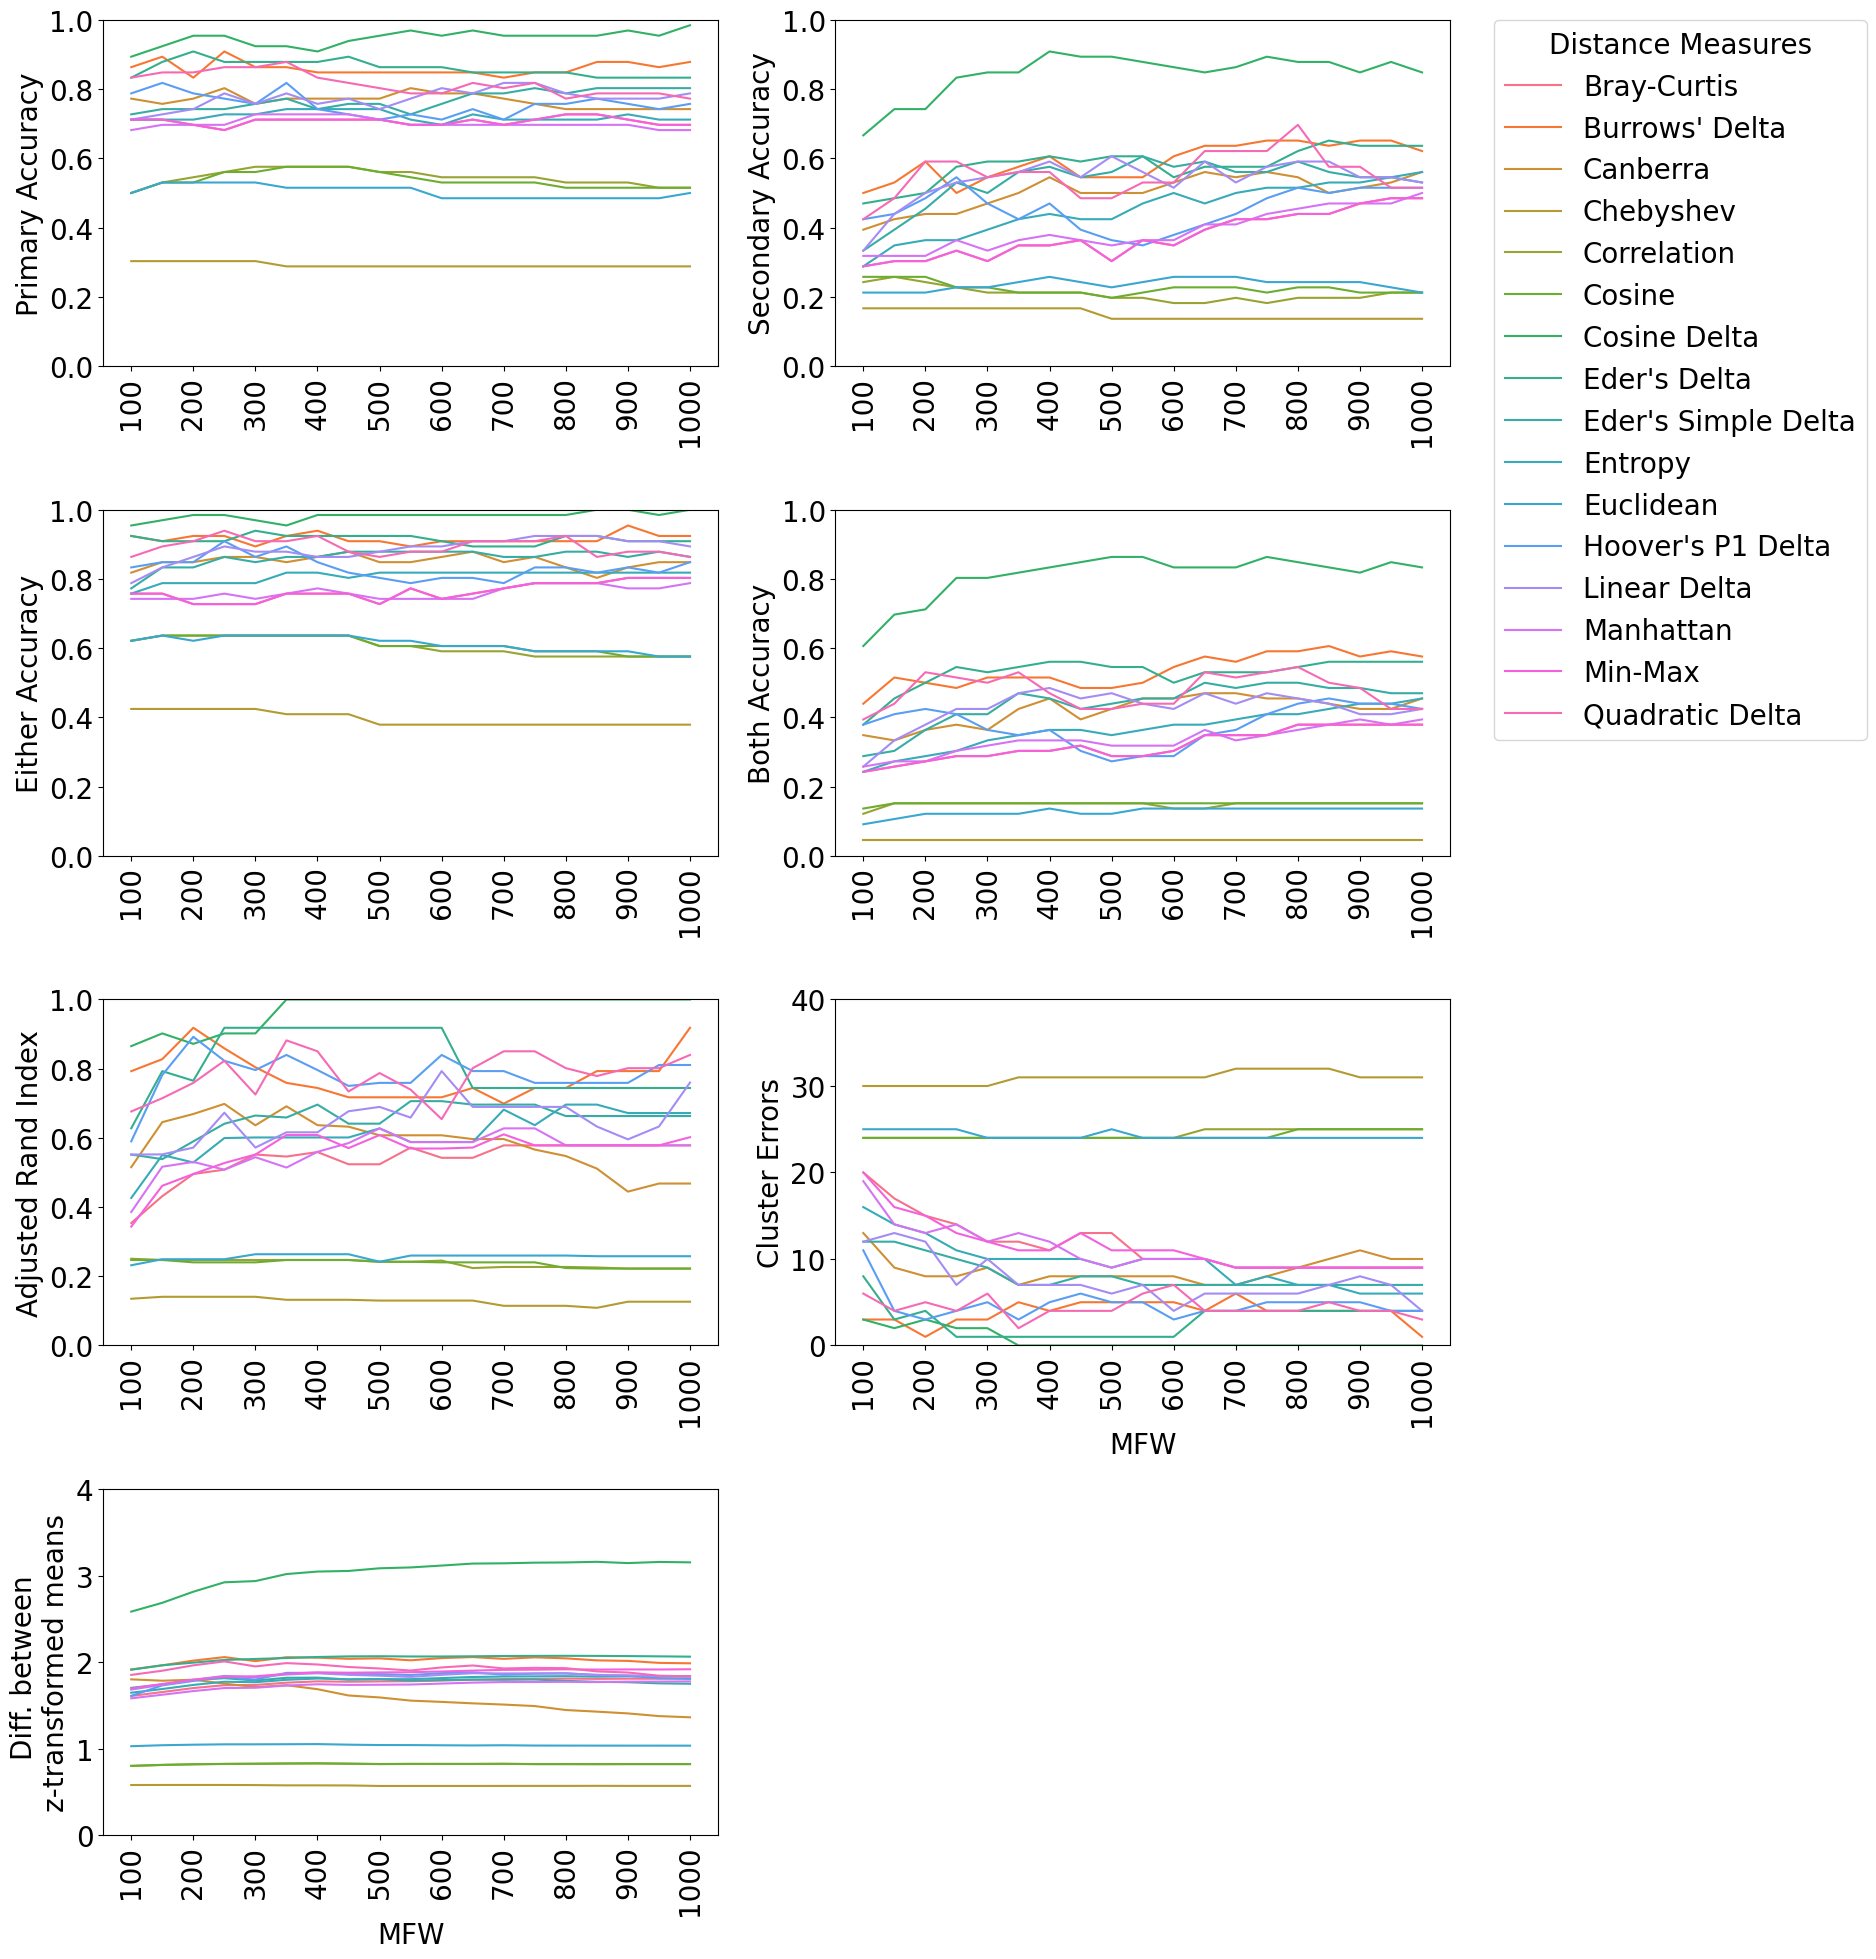

In [220]:
import numpy as np

# 4 subplots, primary_acc, secondary_acc, either_acc, both_acc using facegrid
fig, axes = plt.subplots(4, 2, figsize=(15, 20))

temp_df_eval_ice = eval_ice[(eval_ice["step"] >= 100) & (eval_ice["step"] <= 1000)].sort_values(by=["distance"])

sns.lineplot(x="step", y="primary_acc", hue="distance", data=temp_df_eval_ice, ax=axes[0, 0])
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Primary Accuracy")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].legend_.remove()

sns.lineplot(x="step", y="secondary_acc", hue="distance", data=temp_df_eval_ice, ax=axes[0, 1])
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Secondary Accuracy")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend_.remove()

sns.lineplot(x="step", y="either_acc", hue="distance", data=temp_df_eval_ice, ax=axes[1, 0])
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Either Accuracy")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend_.remove()

sns.lineplot(x="step", y="both_acc", hue="distance", data=temp_df_eval_ice, ax=axes[1, 1])
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Both Accuracy")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].legend_.remove()

sns.lineplot(x="step", y="ari", hue="distance", data=temp_df_eval_ice, ax=axes[2, 0])
axes[2, 0].set_xlabel("")
axes[2, 0].set_ylabel("Adjusted Rand Index")
axes[2, 0].set_ylim(0, 1)
axes[2, 0].legend_.remove()

sns.lineplot(x="step", y="cl_error", hue="distance", data=temp_df_eval_ice, ax=axes[2, 1])
axes[2, 1].set_xlabel("MFW")
axes[2, 1].set_ylabel("Cluster Errors")
axes[2, 1].set_ylim(0, 40)
axes[2, 1].legend_.remove()

sns.lineplot(x="step", y="simple_score", hue="distance", data=temp_df_eval_ice, ax=axes[3, 0])
axes[3, 0].set_xlabel("MFW")
axes[3, 0].set_ylabel("Diff. between \nz-transformed means")
axes[3, 0].set_ylim(0, 4)
axes[3, 0].legend_.remove()

# last one empty
axes[3, 1].axis('off')

# Set x-ticks at ten intervals from 0 to max
max_step = temp_df_eval_ice["step"].max()
x_ticks = np.arange(100, max_step + 10, 100)
for ax in axes.flatten():
    ax.set_xticks(x_ticks)

# rotate x-tick labels for better readability
    for label in ax.get_xticklabels():
        label.set_rotation(90)

# Add a single legend to the upper right of the whole plot, avoiding overlap with subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Distance Measures",
    loc="lower left",
    bbox_to_anchor=(1.0, 0.6125),
)

fig.subplots_adjust(right=0.95)

plt.tight_layout()
plt.show()

In [226]:
eval_all

,distance,feature,step,simple_score,ari,cl_error,cl_correct_pc,primary_acc,secondary_acc,either_acc,both_acc,language,highrank
0,Quadratic Delta,lex_1_rel,2.0,0.698114,0.109361,37.0,0.506667,0.226667,0.120000,0.306667,0.040000,English,6
1,Quadratic Delta,lex_1_rel,3.0,0.900100,0.181731,34.0,0.546667,0.306667,0.240000,0.426667,0.120000,English,6
2,Quadratic Delta,lex_1_rel,4.0,0.938537,0.226697,29.0,0.613333,0.346667,0.240000,0.493333,0.093333,English,6
3,Quadratic Delta,lex_1_rel,5.0,0.953400,0.234483,30.0,0.600000,0.360000,0.240000,0.480000,0.120000,English,6
4,Quadratic Delta,lex_1_rel,6.0,0.981122,0.164339,34.0,0.546667,0.373333,0.200000,0.466667,0.106667,English,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3707,Correlation,lex_1_rel,8000.0,0.821508,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
3708,Correlation,lex_1_rel,8500.0,0.821568,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
3709,Correlation,lex_1_rel,9000.0,0.821643,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
3710,Correlation,lex_1_rel,9500.0,0.821711,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4


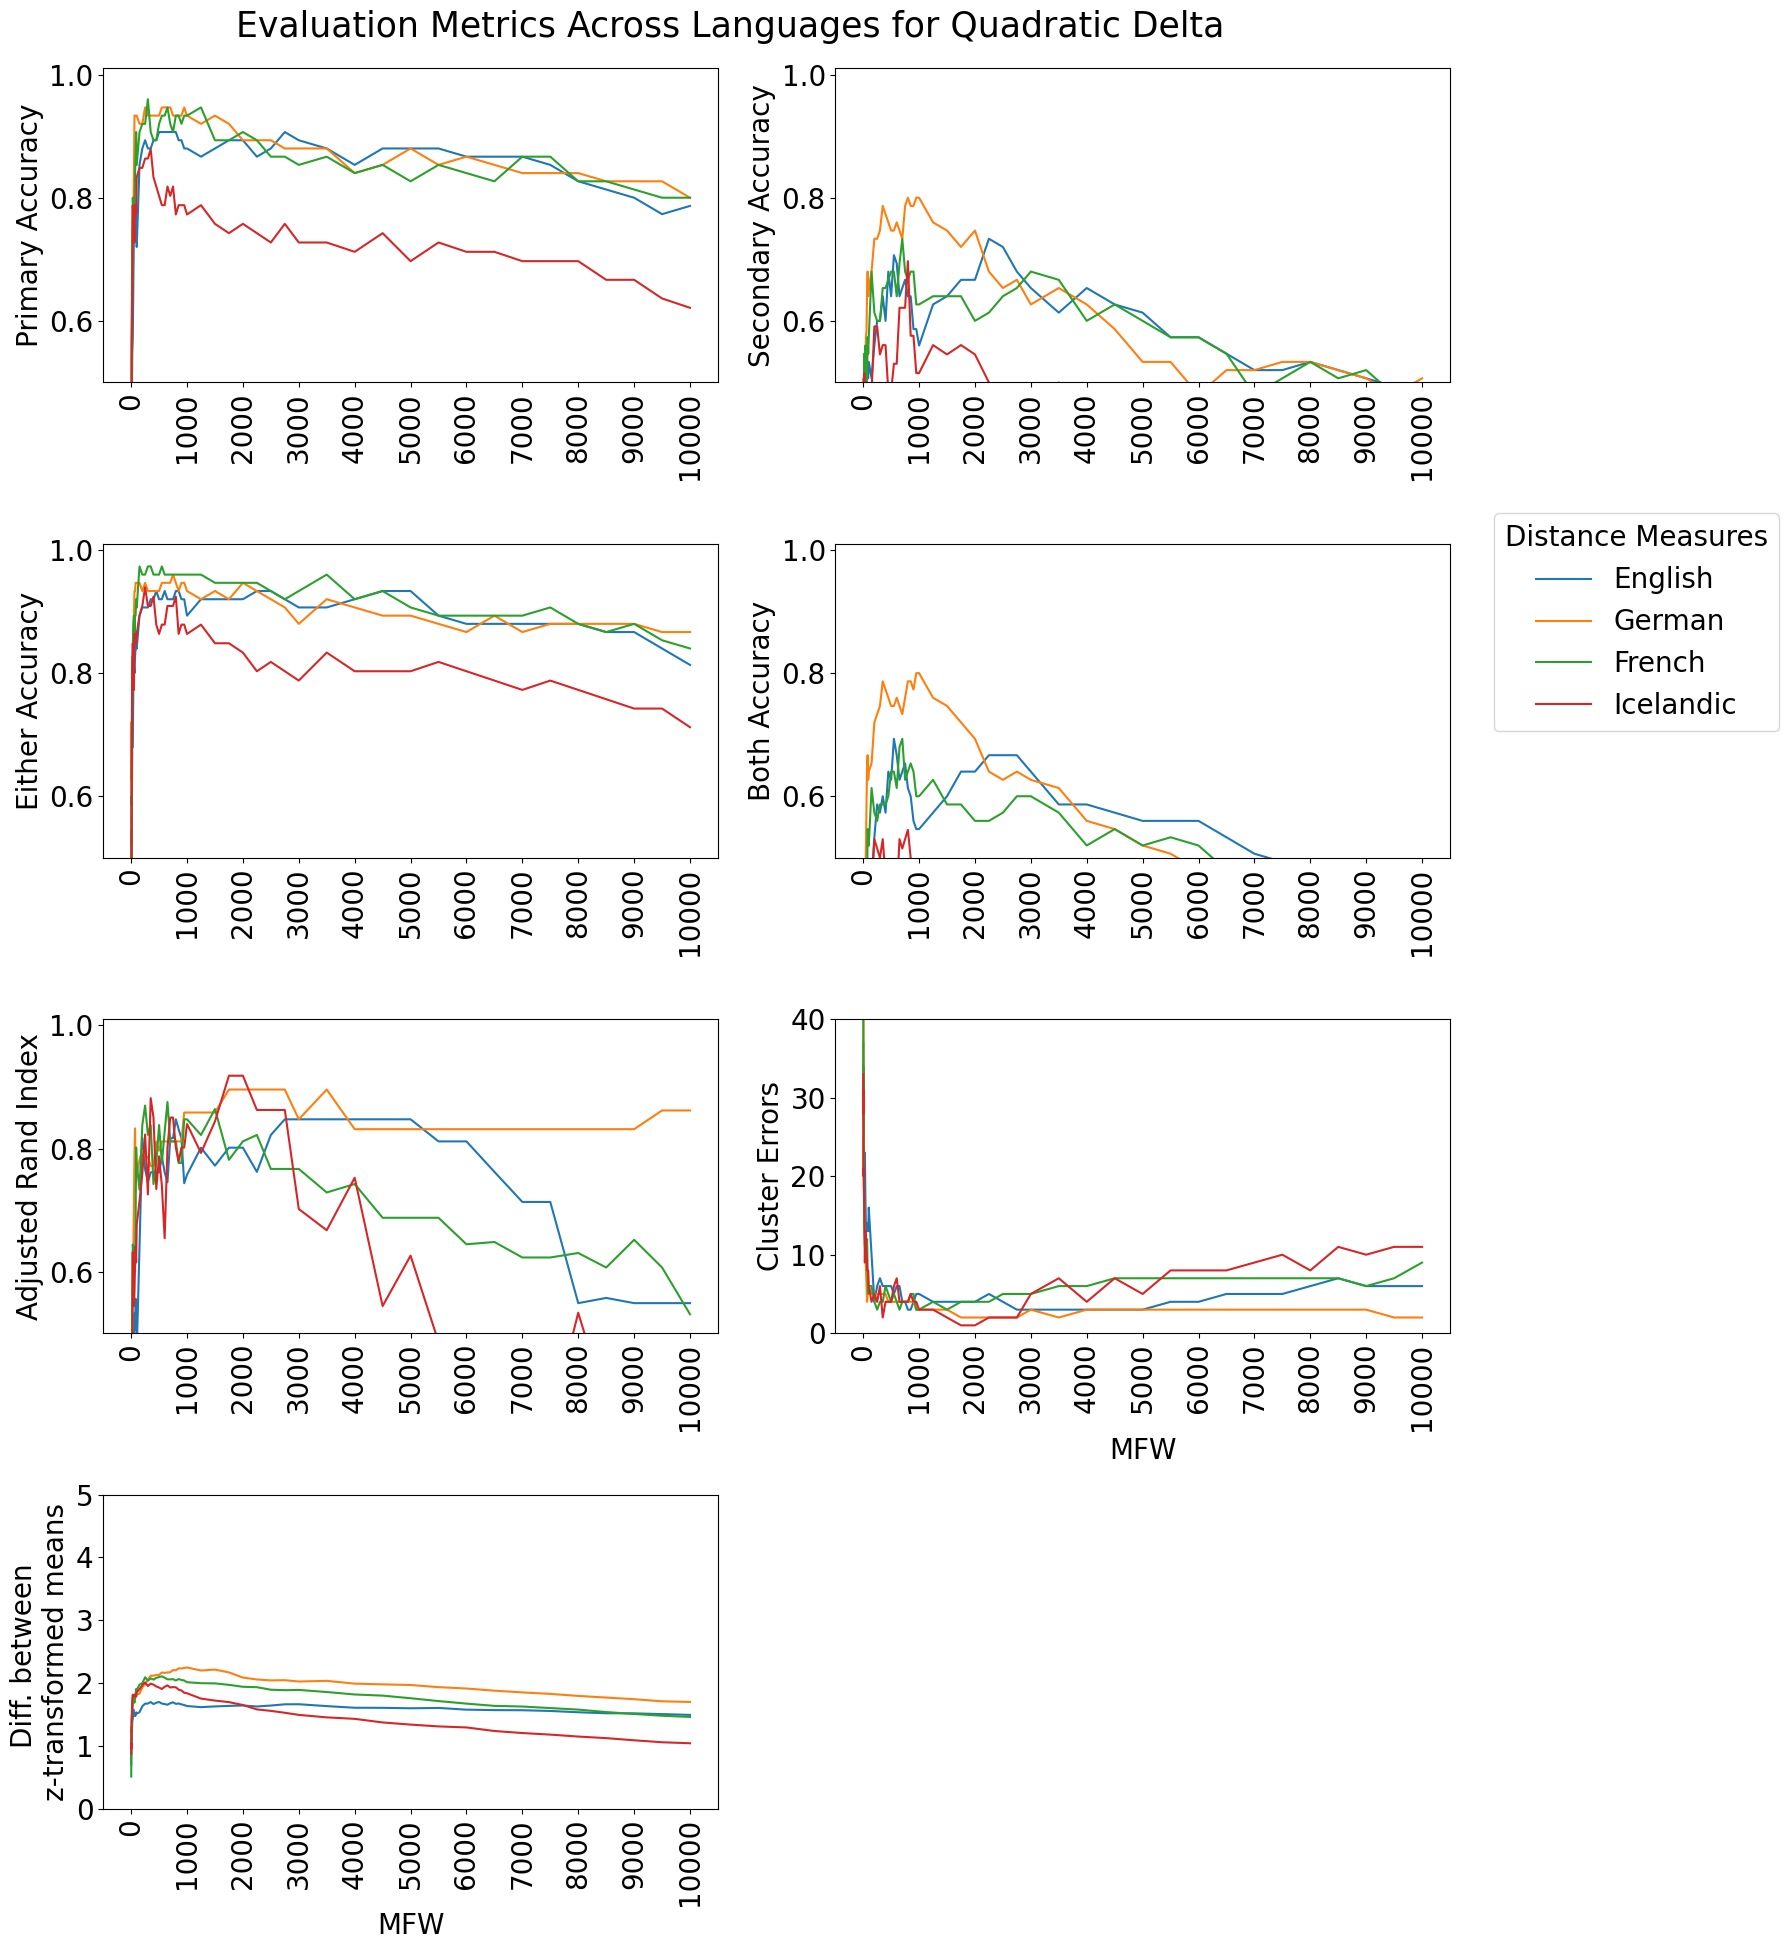

In [375]:
import numpy as np

# 4 subplots, primary_acc, secondary_acc, either_acc, both_acc using facegrid
fig, axes = plt.subplots(4, 2, figsize=(15, 20))

temp_df_eval_all = eval_all[eval_all["distance"] == "Quadratic Delta"]

sns.lineplot(x="step", y="primary_acc", hue="language", data=temp_df_eval_all, ax=axes[0, 0])
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Primary Accuracy")
axes[0, 0].set_ylim(0.5, 1.01)
axes[0, 0].legend_.remove()

sns.lineplot(x="step", y="secondary_acc", hue="language", data=temp_df_eval_all, ax=axes[0, 1])
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Secondary Accuracy")
axes[0, 1].set_ylim(0.5, 1.01)
axes[0, 1].legend_.remove()

sns.lineplot(x="step", y="either_acc", hue="language", data=temp_df_eval_all, ax=axes[1, 0])
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Either Accuracy")
axes[1, 0].set_ylim(0.5, 1.01)
axes[1, 0].legend_.remove()

sns.lineplot(x="step", y="both_acc", hue="language", data=temp_df_eval_all, ax=axes[1, 1])
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Both Accuracy")
axes[1, 1].set_ylim(0.5, 1.01)
axes[1, 1].legend_.remove()

sns.lineplot(x="step", y="ari", hue="language", data=temp_df_eval_all, ax=axes[2, 0])
axes[2, 0].set_xlabel("")
axes[2, 0].set_ylabel("Adjusted Rand Index")
axes[2, 0].set_ylim(0.5, 1.01)
axes[2, 0].legend_.remove()

sns.lineplot(x="step", y="cl_error", hue="language", data=temp_df_eval_all, ax=axes[2, 1])
axes[2, 1].set_xlabel("MFW")
axes[2, 1].set_ylabel("Cluster Errors")
axes[2, 1].set_ylim(0, 40)
axes[2, 1].legend_.remove()

sns.lineplot(x="step", y="simple_score", hue="language", data=temp_df_eval_all, ax=axes[3, 0])
axes[3, 0].set_xlabel("MFW")
axes[3, 0].set_ylabel("Diff. between \nz-transformed means")
axes[3, 0].set_ylim(0, 5)
axes[3, 0].legend_.remove()

# last one empty
axes[3, 1].axis('off')

# Set x-ticks at ten intervals from 0 to max
max_step = 10000
x_ticks = np.arange(0, max_step + 10, 1000)
for ax in axes.flatten():
    ax.set_xticks(x_ticks)


for ax in axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

# Add a single legend to the upper right of the whole plot, avoiding overlap with subplots
handles, labels = axes[0, 0].get_legend_handles_labels()

fig.legend(
    handles,
    labels,
    title="Distance Measures",
    loc="lower left",
    bbox_to_anchor=(1.0, 0.6125),
)

# Title for the entire figure
fig.suptitle("Evaluation Metrics Across Languages for Quadratic Delta", fontsize=25)

fig.subplots_adjust(right=0.95)

plt.tight_layout()
plt.show()

# Inferential Stuff

In [307]:
import pandas as pd
from scipy.stats import kruskal

results = []

for d, sub in eval_all.groupby("distance"):
    groups = [g["simple_score"].fillna(0).values for _, g in sub.groupby("language")]
    stat, p = kruskal(*groups)
    results.append({"distance": d, "stat": stat, "p": p})

pd.DataFrame(results)


,distance,stat,p
0,Bray-Curtis,55.155392,6.361553e-12
1,Burrows' Delta,45.329980,7.872904e-10
2,Canberra,49.852294,8.589306e-11
3,Chebyshev,182.643206,2.369366e-39
4,Correlation,110.765967,7.507377e-24
5,Cosine,124.153371,9.835900e-27
6,Cosine Delta,15.463282,1.460642e-03
7,Eder's Delta,39.424387,1.411075e-08
8,Eder's Simple Delta,53.240565,1.629140e-11
9,Entropy,50.311480,6.857453e-11


In [308]:
import scikit_posthocs as sp

for d, sub in eval_all.groupby("distance"):
    print(f"\nDistance: {d}")
    res = sp.posthoc_dunn(sub, val_col="simple_score", group_col="language", p_adjust="fdr_bh")
    print(res)



Distance: Bray-Curtis
                English        French        German  Icelandic
English    1.000000e+00  7.453726e-10  3.141230e-09   0.005296
French     7.453726e-10  1.000000e+00  7.398819e-01   0.000669
German     3.141230e-09  7.398819e-01  1.000000e+00   0.001700
Icelandic  5.296268e-03  6.687796e-04  1.700409e-03   1.000000

Distance: Burrows' Delta
                English    French        German     Icelandic
English    1.000000e+00  0.000270  1.276632e-07  8.076383e-01
French     2.704646e-04  1.000000  8.920067e-02  5.288555e-04
German     1.276632e-07  0.089201  1.000000e+00  2.527126e-07
Icelandic  8.076383e-01  0.000529  2.527126e-07  1.000000e+00

Distance: Canberra
                English    French        German     Icelandic
English    1.000000e+00  0.000010  2.702322e-07  8.888806e-01
French     9.659431e-06  1.000000  4.431443e-01  1.398297e-05
German     2.702322e-07  0.443144  1.000000e+00  2.944099e-07
Icelandic  8.888806e-01  0.000014  2.944099e-07  1.000000e

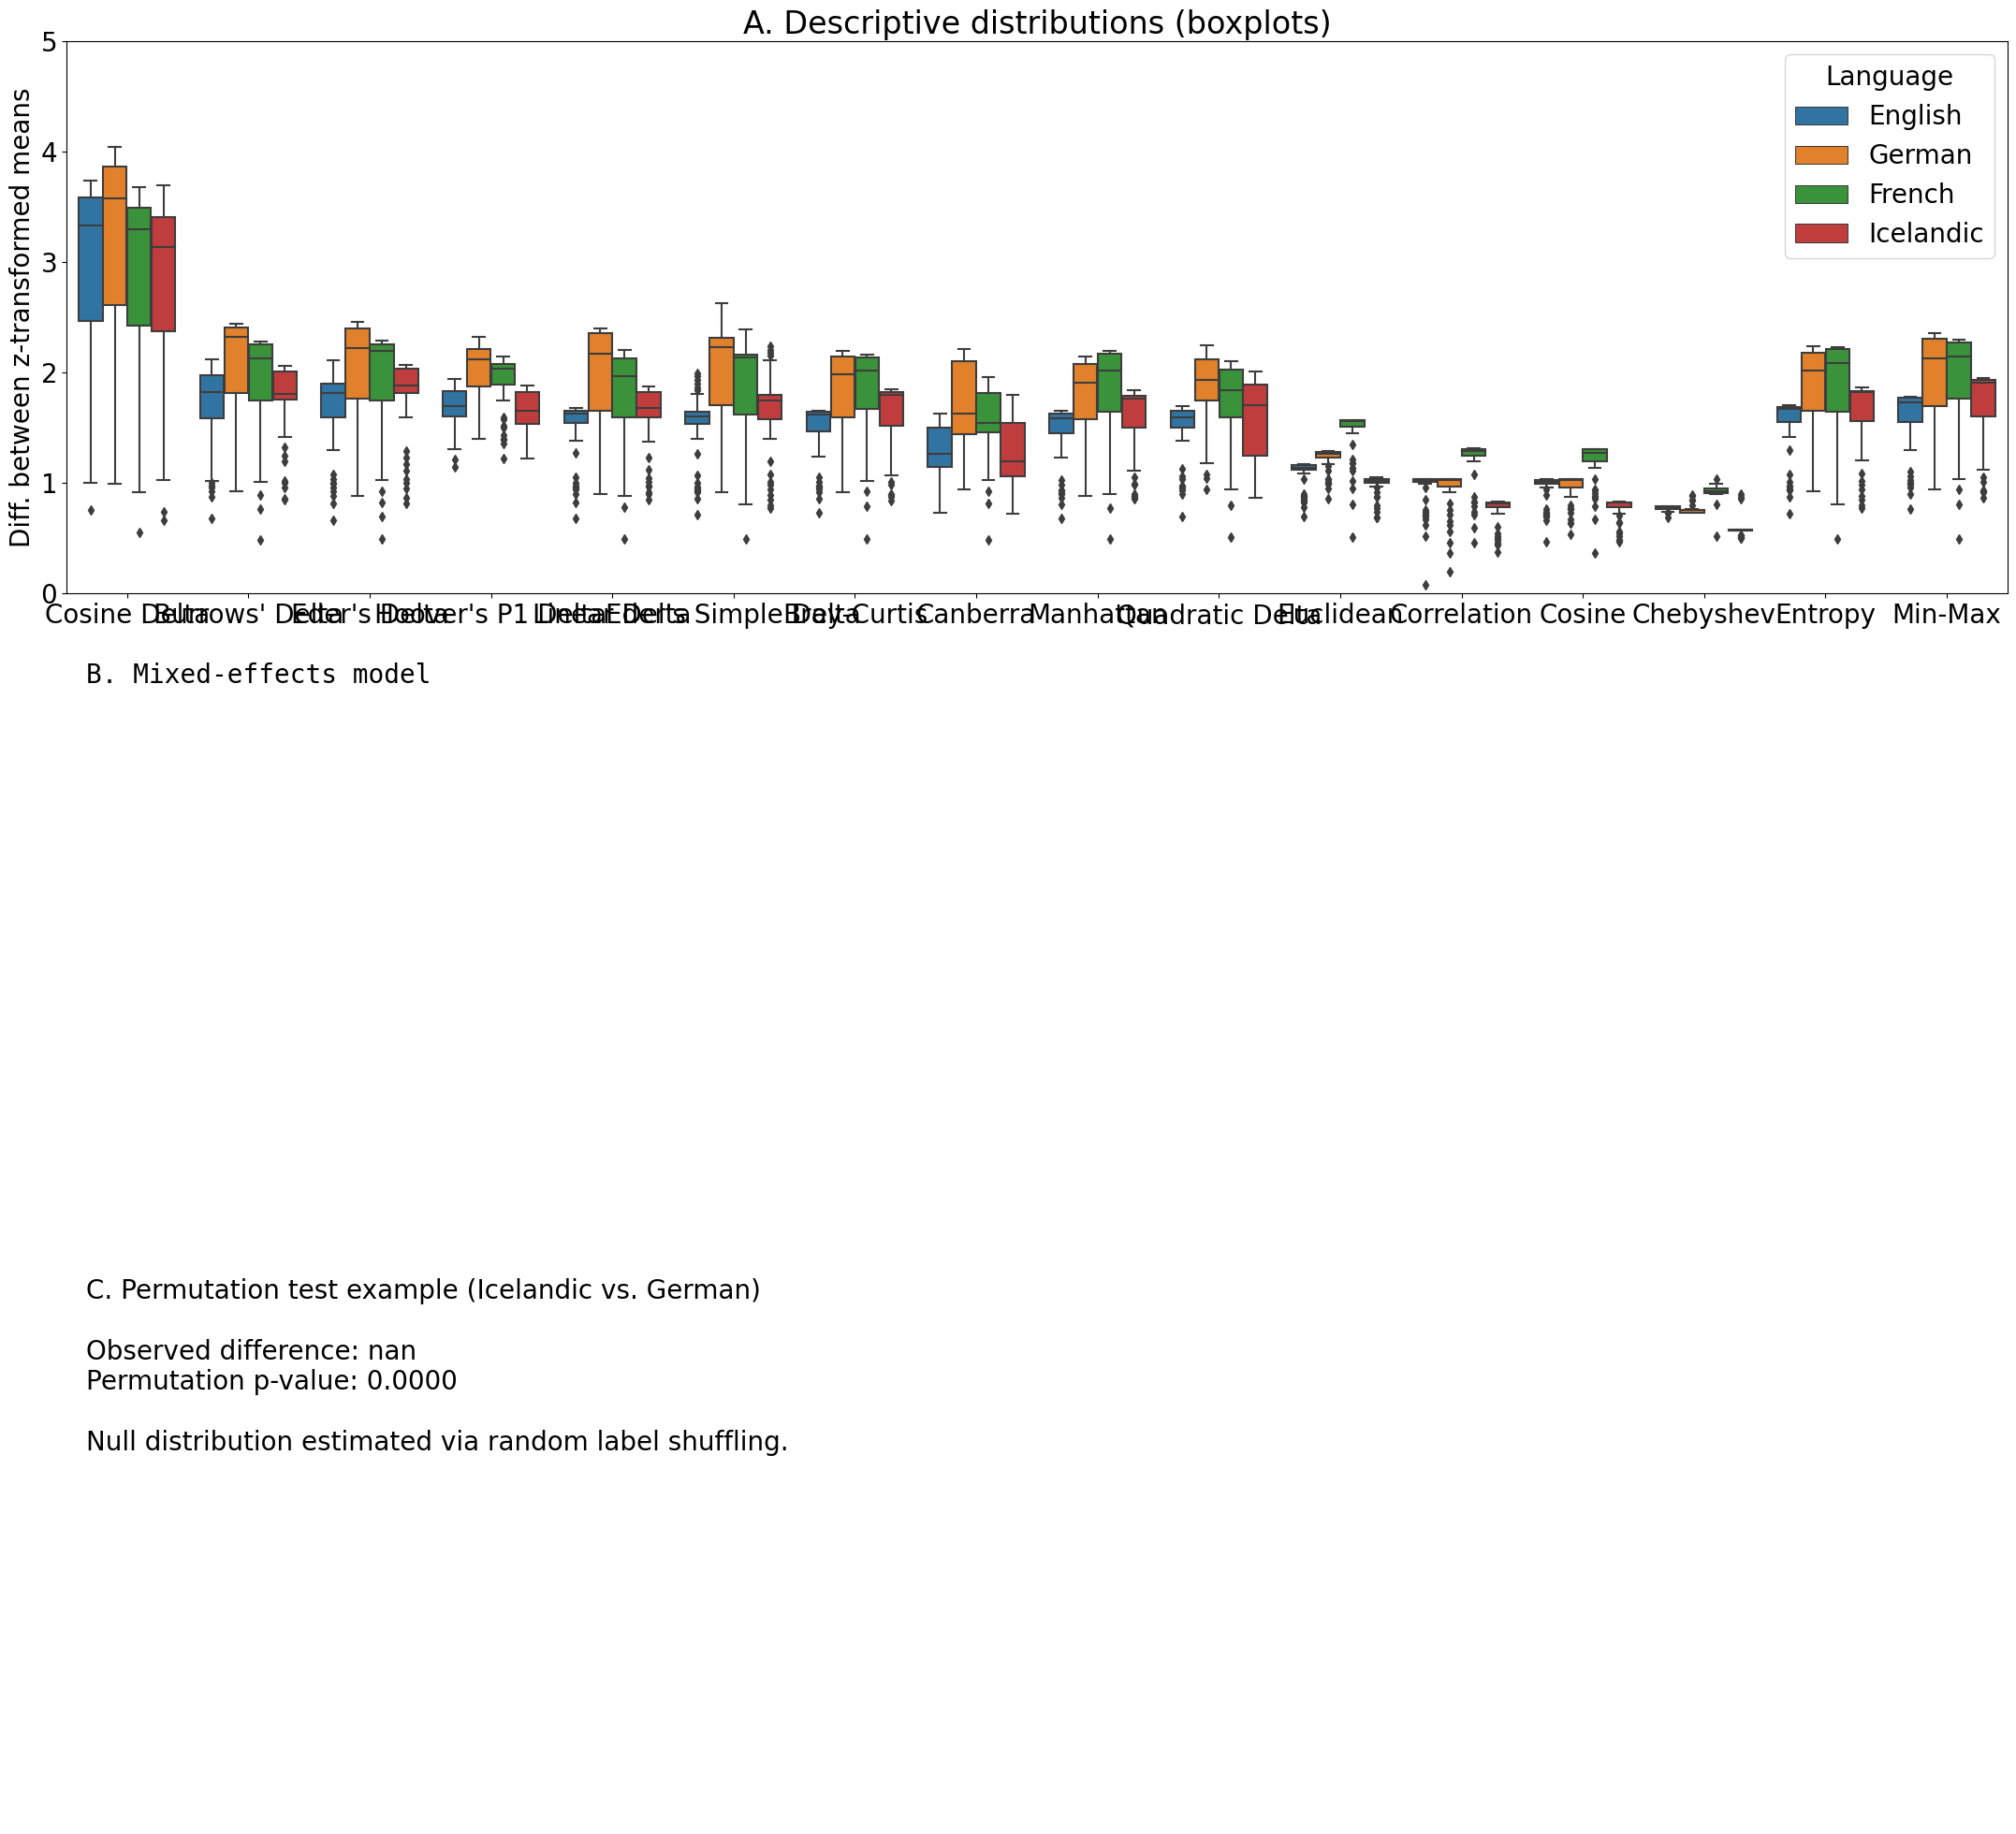

In [299]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

from scipy.stats import kruskal, wilcoxon
from itertools import combinations

import statsmodels.formula.api as smf

# ---------- OPTION 1: Kruskal–Wallis + Wilcoxon (pairwise, paired by distance measure) ----------
def run_nonparametric_tests(df):
    results = {}

    # Overall Kruskal–Wallis (language effect across all scores)
    groups = [g["simple_score"].values for _, g in df.groupby("language")]
    kw_stat, kw_p = kruskal(*groups)
    results["kruskal"] = (kw_stat, kw_p)

    # Pairwise Wilcoxon SIGNED-RANK — pairing by distance measure
    pair_results = []
    for lang1, lang2 in combinations(df["language"].unique(), 2):
        d1 = df[df.language == lang1].sort_values("distance")["simple_score"].values
        d2 = df[df.language == lang2].sort_values("distance")["simple_score"].values
        
        stat, p = wilcoxon(d1, d2)
        pair_results.append((lang1, lang2, stat, p))

    results["pairwise"] = pair_results
    return results


# ---------- OPTION 3: Mixed-effects model ----------
def run_mixed_effects(df):
    # language = fixed effect
    # distance (measure) = random intercept
    model = smf.mixedlm(
        "simple_score ~ language",
        data=df,
        groups=df["distance"]
    ).fit()
    return model


# ---------- OPTION 4: Permutation test ----------
def permutation_test(df, langA, langB, n_perm=5000, random_state=42):
    rng = np.random.default_rng(random_state)

    a = df[df.language == langA]["simple_score"].values
    b = df[df.language == langB]["simple_score"].values

    observed = np.mean(a) - np.mean(b)

    pooled = np.concatenate([a, b])
    count = 0

    for _ in range(n_perm):
        rng.shuffle(pooled)
        perm_a = pooled[:len(a)]
        perm_b = pooled[len(a):]
        perm_diff = np.mean(perm_a) - np.mean(perm_b)
        if abs(perm_diff) >= abs(observed):
            count += 1

    p_value = count / n_perm
    return observed, p_value


# ---------- RUN ANALYSES ----------
np_results = run_nonparametric_tests(eval_all)
#mixed_model = run_mixed_effects(eval_all)

perm_example = permutation_test(eval_all, "Icelandic", "German", n_perm=5000)


# ---------- PLOTTING ----------
fig, axes = plt.subplots(figsize=(22, 20), nrows=3, ncols=1)

# 1) Boxplots (descriptive)
sns.boxplot(
    x="distance",
    y="simple_score",
    hue="language",
    data=eval_all,
    order=refcor_highrank_all,
    ax=axes[0]
)
axes[0].set_ylabel("Diff. between z-transformed means")
axes[0].set_xlabel("")
axes[0].set_title("A. Descriptive distributions (boxplots)")
axes[0].set_ylim(0, 5)
axes[0].legend(title="Language")

# 2) Mixed-effects model summary text
axes[1].axis("off")
summary_text = ""#mixed_model.summary().as_text()
axes[1].text(
    0.01, 0.99,
    "B. Mixed-effects model\n\n" + summary_text,
    va="top",
    family="monospace"
)

# 3) Permutation test illustration
axes[2].axis("off")
axes[2].text(
    0.01, 0.99,
    (
        "C. Permutation test example (Icelandic vs. German)\n\n"
        f"Observed difference: {perm_example[0]:.3f}\n"
        f"Permutation p-value: {perm_example[1]:.4f}\n\n"
        "Null distribution estimated via random label shuffling."
    ),
    va="top"
)

plt.tight_layout()
plt.show()


# DTW

In [310]:
pip install dtaidistance

                                              0.0/985.8 kB ? eta -:--:--
                                              10.2/985.8 kB ? eta -:--:--
                                           20.5/985.8 kB 217.9 kB/s eta 0:00:05
     -                                     30.7/985.8 kB 217.9 kB/s eta 0:00:05
     -                                     51.2/985.8 kB 262.6 kB/s eta 0:00:04
     ---                                  102.4/985.8 kB 420.8 kB/s eta 0:00:03
     -----------                            286.7/985.8 kB 1.1 MB/s eta 0:00:01
     ---------------------                  563.2/985.8 kB 1.9 MB/s eta 0:00:01
     -------------------------------------  983.0/985.8 kB 3.0 MB/s eta 0:00:01
     -------------------------------------- 985.8/985.8 kB 2.6 MB/s eta 0:00:00
  Installing build dependencies: started
  Installing build dependencies: finished with status 'done'
  Getting requirements to build wheel: started
  Getting requirements to build wheel: finished with status 'don

In [ ]:
import pandas as pd
import numpy as np
from dtaidistance import dtw
import matplotlib.pyplot as plt
import seaborn as sns

# compare ari cosine delta between the foiur langauges using dtw
eval_all_cd = eval_all[eval_all["distance"] == "Cosine Delta"]
languages = eval_all_cd["language"].unique()
ari_series = {lang: eval_all_cd[eval_all_cd["language"] == lang].sort_values("step")["simple_score"].values for lang in languages}
dtw_results = []
dtw_matrix = pd.DataFrame(index=languages, columns=languages)
dtw_matrix[:] = 0.0
for lang1, lang2 in combinations(languages, 2):
    series1 = ari_series[lang1]
    series2 = ari_series[lang2]
    distance = dtw.distance(series1, series2)
    dtw_results.append({"Language 1": lang1, "Language 2": lang2, "DTW Distance": distance})
    dtw_matrix.loc[lang1, lang2] = distance
    dtw_matrix.loc[lang2, lang1] = distance

dtw_df = pd.DataFrame(dtw_results)
print(dtw_df)
print(dtw_matrix)


  Language 1 Language 2  DTW Distance
0    English     German      1.082058
1    English     French      0.397314
2    English  Icelandic      0.370515
3     German     French      1.342186
4     German  Icelandic      1.290533
5     French  Icelandic      0.332818
            English    German    French Icelandic
English         0.0  1.082058  0.397314  0.370515
German     1.082058       0.0  1.342186  1.290533
French     0.397314  1.342186       0.0  0.332818
Icelandic  0.370515  1.290533  0.332818       0.0


In [323]:
eval_all

,distance,feature,step,simple_score,ari,cl_error,cl_correct_pc,primary_acc,secondary_acc,either_acc,both_acc,language,highrank
0,Quadratic Delta,lex_1_rel,2.0,0.698114,0.109361,37.0,0.506667,0.226667,0.120000,0.306667,0.040000,English,6
1,Quadratic Delta,lex_1_rel,3.0,0.900100,0.181731,34.0,0.546667,0.306667,0.240000,0.426667,0.120000,English,6
2,Quadratic Delta,lex_1_rel,4.0,0.938537,0.226697,29.0,0.613333,0.346667,0.240000,0.493333,0.093333,English,6
3,Quadratic Delta,lex_1_rel,5.0,0.953400,0.234483,30.0,0.600000,0.360000,0.240000,0.480000,0.120000,English,6
4,Quadratic Delta,lex_1_rel,6.0,0.981122,0.164339,34.0,0.546667,0.373333,0.200000,0.466667,0.106667,English,6
...,...,...,...,...,...,...,...,...,...,...,...,...,...
3707,Correlation,lex_1_rel,8000.0,0.821508,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
3708,Correlation,lex_1_rel,8500.0,0.821568,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
3709,Correlation,lex_1_rel,9000.0,0.821643,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4
3710,Correlation,lex_1_rel,9500.0,0.821711,0.222242,25.0,0.621212,0.530303,0.227273,0.606061,0.151515,Icelandic,4


In [350]:
import pandas as pd
import numpy as np
from dtaidistance import dtw
from itertools import combinations

languages = eval_all["language"].unique()
dtw_matrix = pd.DataFrame(index=languages, columns=languages, dtype=float)
dtw_matrix[:] = 0.0

# Compute DTW distances for all pairs, averaged across distance measures
for lang1, lang2 in combinations(languages, 2):
    distances = []
    for dist in eval_all["distance"].unique():
        eval_dm = eval_all[(eval_all["distance"] == dist)]

        series1 = eval_dm[eval_dm["language"] == lang1].sort_values("step")["both_acc"].values
        # replace nan with 0
        series1 = np.nan_to_num(series1, nan=0.0)
        series2 = eval_dm[eval_dm["language"] == lang2].sort_values("step")["both_acc"].values
        series2 = np.nan_to_num(series2, nan=0.0)
        distances.append(dtw.distance(series1, series2))
    # Aggregate across distance measures (mean)
    mean_distance = np.mean(distances)
    dtw_matrix.loc[lang1, lang2] = mean_distance
    dtw_matrix.loc[lang2, lang1] = mean_distance

# only print 2f.
display(dtw_matrix.round(2))


,English,German,French,Icelandic
English,0.00,0.54,0.41,0.62
German,0.54,0.00,0.37,1.23
French,0.41,0.37,0.00,0.90
Icelandic,0.62,1.23,0.90,0.00


In [330]:
temp_df

0       0.109361
1       0.181731
2       0.226697
3       0.234483
4       0.164339
          ...   
3707    0.222242
3708    0.222242
3709    0.222242
3710    0.222242
3711    0.222242
Name: ari, Length: 3712, dtype: float64

In [333]:
# averege trajectories for each language by eval score
eval_all_avg = eval_all.groupby(["language", "step"]).agg({
    "simple_score": "mean",
    "cl_error": "mean",
    "ari": "mean",
    "primary_acc": "mean",
    "secondary_acc": "mean",
    "either_acc": "mean",
    "both_acc": "mean"
}).reset_index()

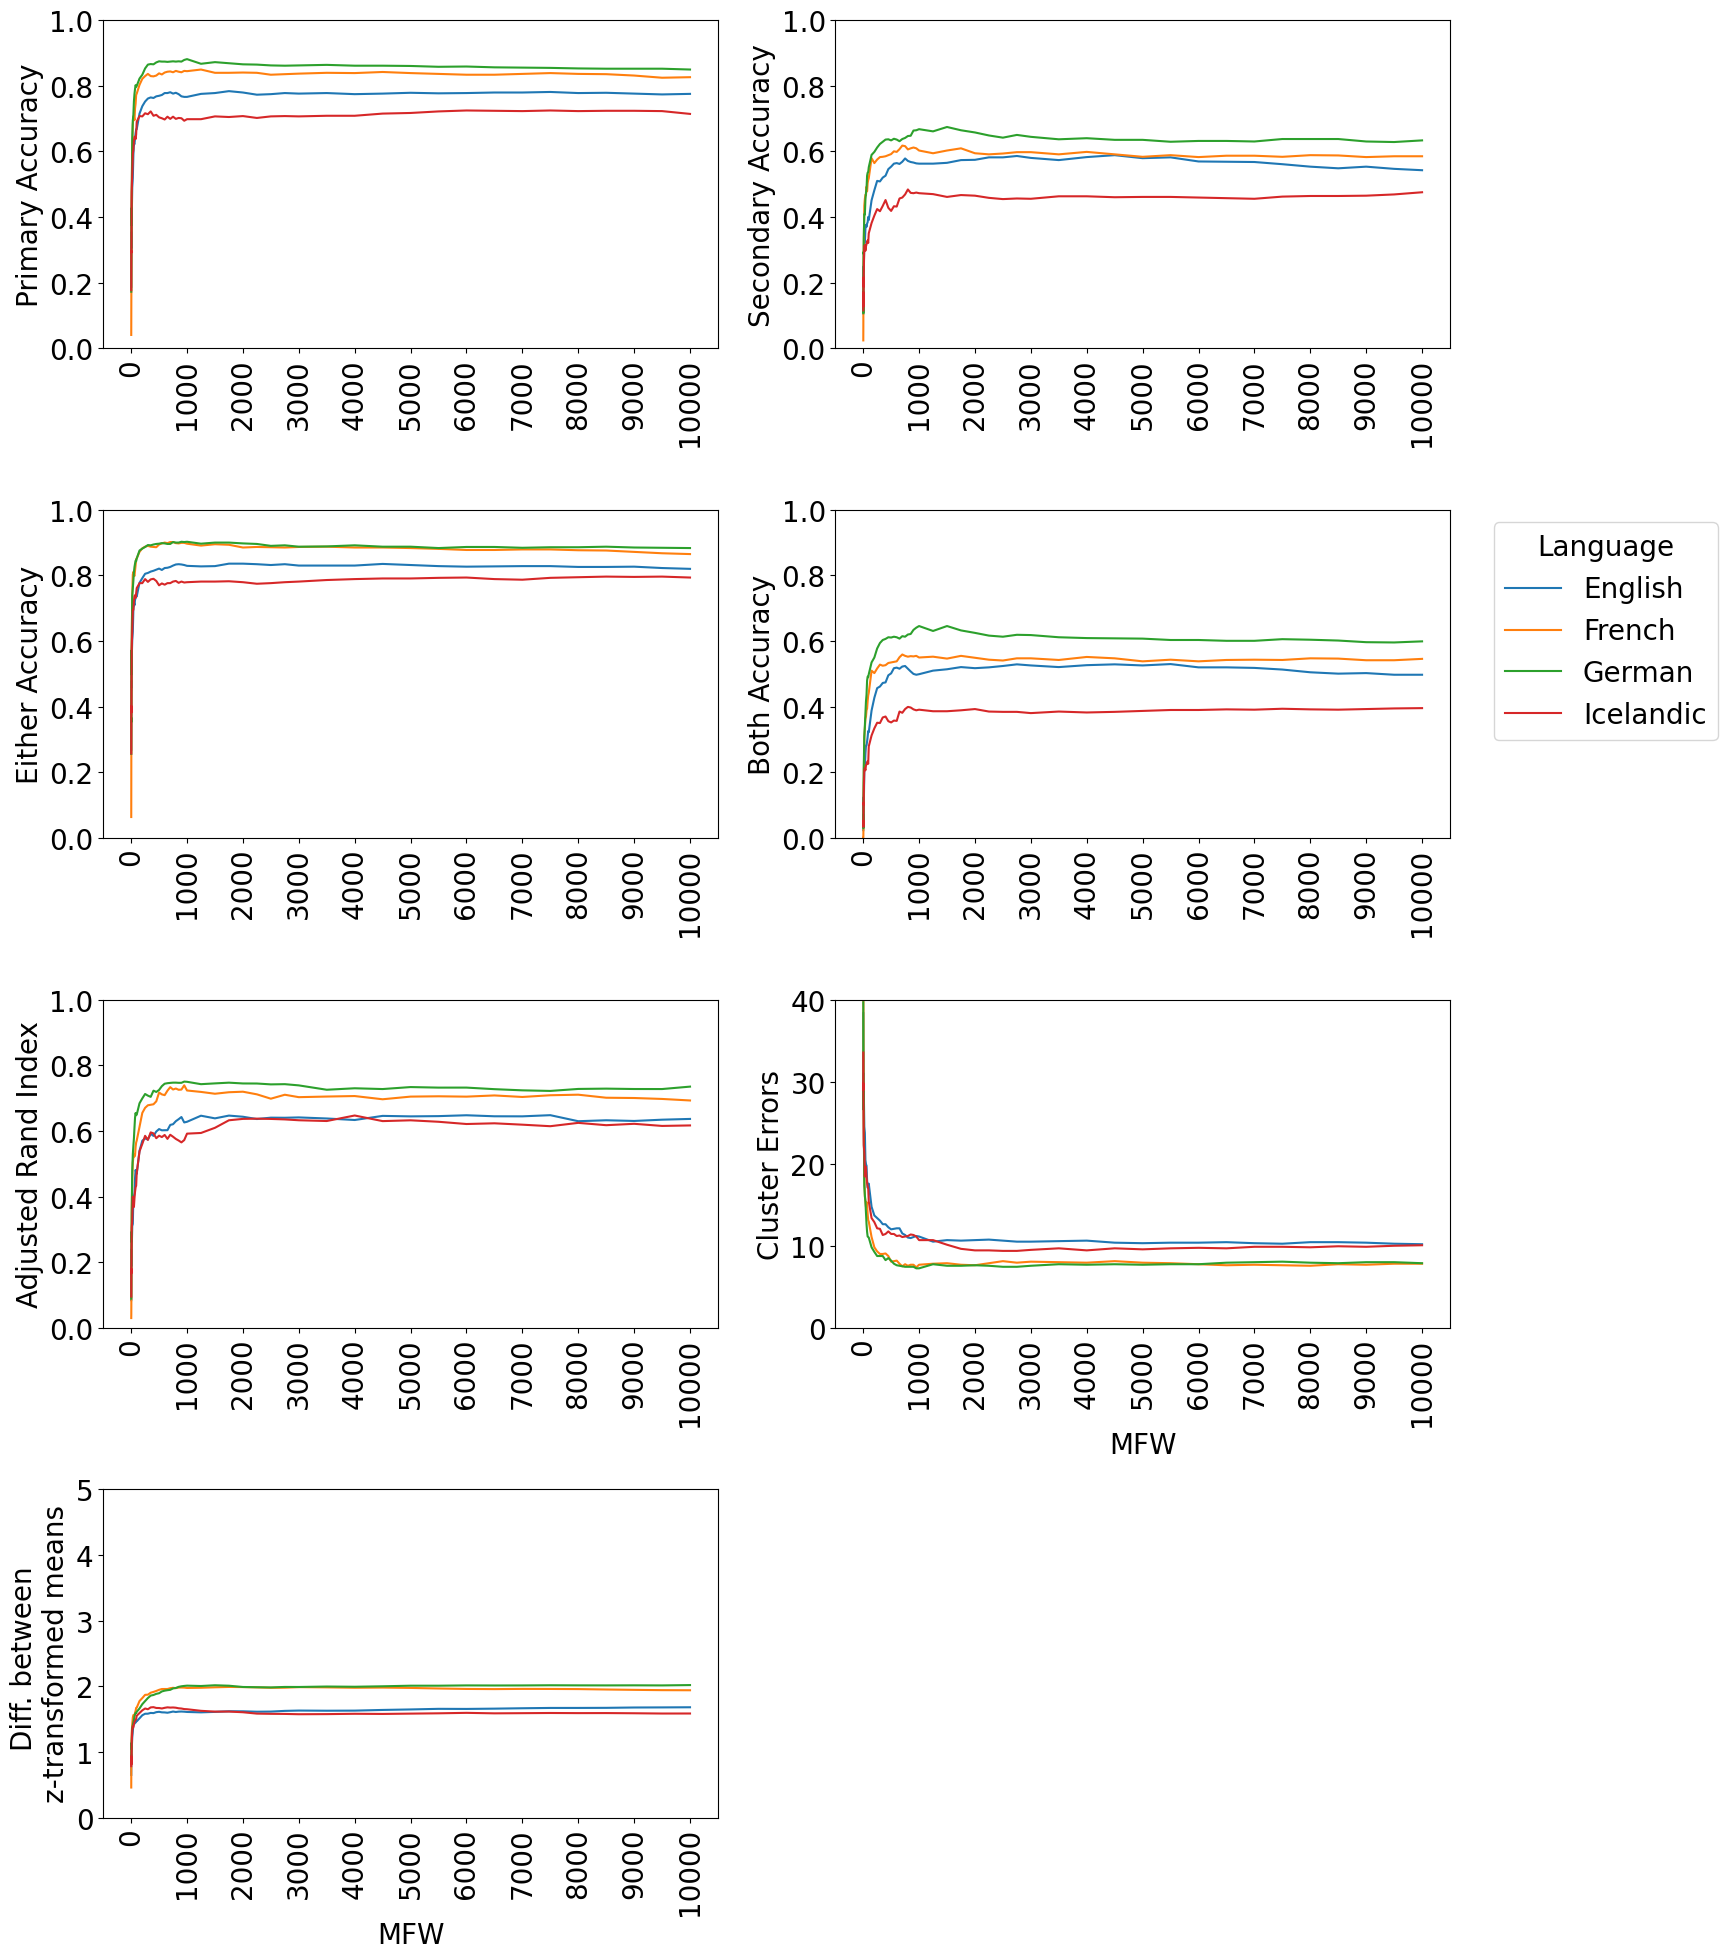

In [336]:
# plot average trajectories for each language by eval score
fig, axes = plt.subplots(4, 2, figsize=(15, 20))
sns.lineplot(x="step", y="primary_acc", hue="language", data=eval_all_avg, ax=axes[0, 0])
axes[0, 0].set_xlabel("")
axes[0, 0].set_ylabel("Primary Accuracy")
axes[0, 0].set_ylim(0, 1)
axes[0, 0].legend_.remove()
sns.lineplot(x="step", y="secondary_acc", hue="language", data=eval_all_avg, ax=axes[0, 1])
axes[0, 1].set_xlabel("")
axes[0, 1].set_ylabel("Secondary Accuracy")
axes[0, 1].set_ylim(0, 1)
axes[0, 1].legend_.remove()
sns.lineplot(x="step", y="either_acc", hue="language", data=eval_all_avg, ax=axes[1, 0])
axes[1, 0].set_xlabel("")
axes[1, 0].set_ylabel("Either Accuracy")
axes[1, 0].set_ylim(0, 1)
axes[1, 0].legend_.remove()
sns.lineplot(x="step", y="both_acc", hue="language", data=eval_all_avg, ax=axes[1, 1])
axes[1, 1].set_xlabel("")
axes[1, 1].set_ylabel("Both Accuracy")
axes[1, 1].set_ylim(0, 1)
axes[1, 1].legend_.remove()
sns.lineplot(x="step", y="ari", hue="language", data=eval_all_avg, ax=axes[2, 0])
axes[2, 0].set_xlabel("")
axes[2, 0].set_ylabel("Adjusted Rand Index")
axes[2, 0].set_ylim(0, 1)
axes[2, 0].legend_.remove()
sns.lineplot(x="step", y="cl_error", hue="language", data=eval_all_avg, ax=axes[2, 1])
axes[2, 1].set_xlabel("MFW")
axes[2, 1].set_ylabel("Cluster Errors")
axes[2, 1].set_ylim(0, 40)
axes[2, 1].legend_.remove()
sns.lineplot(x="step", y="simple_score", hue="language", data=eval_all_avg, ax=axes[3, 0])
axes[3, 0].set_xlabel("MFW")
axes[3, 0].set_ylabel("Diff. between \nz-transformed means")
axes[3, 0].set_ylim(0, 5)
axes[3, 0].legend_.remove()
# last one empty
axes[3, 1].axis('off')
# Set x-ticks at ten intervals from 0 to max
max_step = 10000
x_ticks = np.arange(0, max_step + 10, 1000)
for ax in axes.flatten():
    ax.set_xticks(x_ticks)

for ax in axes.flatten():
    for label in ax.get_xticklabels():
        label.set_rotation(90)

# Add a single legend to the upper right of the whole plot, avoiding overlap with subplots
handles, labels = axes[0, 0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    title="Language",
    loc="lower left",
    bbox_to_anchor=(1.0, 0.6125),
)
fig.subplots_adjust(right=0.95)
plt.tight_layout()
plt.show()

In [339]:
# perform dtw on the averaged trajectories
dtw_matrix_avg = pd.DataFrame(index=languages, columns=languages, dtype=float)
dtw_matrix_avg[:] = 0.0
for lang1, lang2 in combinations(languages, 2):
    series1 = eval_all_avg[eval_all_avg["language"] == lang1].sort_values("step")["cl_error"].values
    series1 = np.nan_to_num(series1, nan=0.0)
    series2 = eval_all_avg[eval_all_avg["language"] == lang2].sort_values("step")["cl_error"].values
    series2 = np.nan_to_num(series2, nan=0.0)
    distance = dtw.distance(series1, series2)
    dtw_matrix_avg.loc[lang1, lang2] = distance
    dtw_matrix_avg.loc[lang2, lang1] = distance
print(dtw_matrix_avg)

             English     German     French  Icelandic
English     0.000000  16.808986  17.035342   7.354891
German     16.808986   0.000000   6.209495  14.376160
French     17.035342   6.209495   0.000000  19.643106
Icelandic   7.354891  14.376160  19.643106   0.000000


In [ ]:
# plotly box
import plotly.express as px
fig = px.box(
    eval_all,
    x="distance",
    y="ari",
    color="language",
    title="Distribution of Adjusted Rand Index (ARI) Scores Across Languages and Distance Measures",
    labels={"ari": "ARI Score", "distance": "Distance Measure"},
    height=600,
    width=1000
)
fig.update_yaxes(range=[0, 1.1])
fig.show()

In [363]:
# plot average trajectories for each language by eval score in plotly
import plotly.express as px
fig = px.line(
    eval_all_avg,
    x="step",
    y="ari",
    color="language",
    title="Average Adjusted Rand Index (ARI) Trajectories Across Languages",
    labels={"ari": "ARI Score", "step": "Number of Most Frequent Words (MFW)"},
    height=600,
    width=1000
)
#fig.show()
# save
fig.write_html("../average_ari_trajectories.html")

In [364]:
# simple score
fig = px.line(
    eval_all_avg,
    x="step",
    y="simple_score",
    color="language",
    title="Average Simple Score Trajectories Across Languages",
    labels={"simple_score": "Diff. between z-transformed means", "step": "Number of Most Frequent Words (MFW)"},
    height=600,
    width=1000
)
#fig.show()
# save
fig.write_html("../average_simple_score_trajectories.html")